<a href="https://colab.research.google.com/github/EyaRIAHI-BE/eya-riahi-portfolio/blob/main/Task_Based_fMRI_GLM_SPM_Auditory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet Académique — Task-Based fMRI Analysis Using a General Linear Model (GLM)
**Neuroimagerie fonctionnelle · Traitement du signal cérébral · Modélisation statistique · Python**

---

## 1. Présentation générale

### Titre
**Analyse statistique de l’activation cérébrale en IRM fonctionnelle par modèle linéaire général (GLM) — application au jeu de données SPM Auditory.**

### Objectif
Développer un pipeline complet, reproductible et rigoureux d’analyse d’IRM fonctionnelle (IRMf) permettant d’étudier la réponse hémodynamique cérébrale associée à une stimulation auditive. Ce projet repose sur le jeu de données public **SPM Auditory (MoAEpilot)**, accessible via la bibliothèque **Nilearn** en Python.

L’analyse suit les étapes méthodologiques standards d'une analyse de premier niveau (*First-Level Analysis* / intra-sujet) :
1. **Exploration et caractérisation** des images fonctionnelles 4D, de l'image anatomique T1 et du protocole expérimental.
2. **Contrôle qualité initial (QC)** spatial et temporel du signal BOLD (*Blood-Oxygen-Level Dependent*), incluant l'intensité globale, le rapport signal-sur-bruit temporel (**tSNR**) et le **DVARS**.
3. **Modélisation du protocole expérimental** par convolution des créneaux de stimulation (`listening`) avec la fonction de réponse hémodynamique canonique (**HRF**) et prise en compte des dérives temporelles basses fréquences (*cosine drift*).
4. **Ajustement d'un Modèle Linéaire Général (GLM)** voxel par voxel avec modélisation de l'autocorrélation temporelle des résidus selon un processus **AR(1)**.
5. **Estimation du contraste expérimental** ($C = \text{Écoute} - \text{Ligne de base}$), calcul des cartes de taille d'effet ($\hat{\beta}$) et des cartes statistiques ($t$ et $Z$).
6. **Correction pour comparaisons multiples** (contrôle du taux de fausses découvertes **FDR** et contrôle **Bonferroni / FWER**), extraction des clusters d'activation et inspection de l'ajustement temporel du modèle au pic d'activation.
7. **Exportation structurée** des cartes NIfTI, des tableaux synthétiques CSV, des figures haute résolution et du rapport interactif HTML.

> **Limite méthodologique importante :** Il s’agit d’un jeu de données historique et pédagogique portant sur **un seul participant** ($N = 1$). Les résultats illustrent une analyse intra-sujet de premier niveau (*fixed-effects single-subject analysis*), mais ne permettent en aucun cas de généraliser les conclusions à l'échelle d'une population (*random-effects group analysis*).

---

## 2. Base de données et Environnement technique

### Base de données : SPM Auditory / MoAEpilot
* **Source :** [Documentation officielle SPM — Auditory fMRI data (MoAEpilot)](https://www.fil.ion.ucl.ac.uk/spm/data/auditory/)
* **Référence Nilearn :** [Nilearn Single-Subject Single-Run GLM Tutorial](https://nilearn.github.io/stable/auto_examples/00_tutorials/plot_single_subject_single_run.html)
* **Protocole :** Paradigme en blocs alternant des périodes de repos implicite (silence de $42\text{ s}$, soit 6 volumes) et des périodes de stimulation auditive (`listening` de $42\text{ s}$, soit 6 volumes : écoute de mots bi-syllabiques présentés à un rythme de 60 mots/minute).

### Stack technique
| Catégorie | Technologies |
| :--- | :--- |
| **Langage** | Python 3 |
| **Traitement des données** | `NumPy`, `Pandas`, `SciPy` |
| **Neuroimagerie** | `Nilearn`, `NiBabel` |
| **Modélisation statistique** | `nilearn.glm.first_level` (`FirstLevelModel`, HRF, AR(1), FDR) |
| **Visualisation** | `Matplotlib`, `nilearn.plotting` |
| **Format des images** | NIfTI (`.nii`, `.nii.gz`) |

In [2]:
# Installation des dépendances manquantes dans Colab
!pip install -q nilearn

# Configuration de l'environnement et importation des bibliothèques
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import nibabel as nib
import nilearn
from nilearn import datasets, image, masking, plotting
from nilearn.glm.first_level import (
    FirstLevelModel,
    make_first_level_design_matrix,
    compute_regressor,
)
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Style graphique académique
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Création des répertoires d'exportation des livrables
OUTPUT_DIR = Path("outputs_spm_auditory")
NIFTI_DIR = OUTPUT_DIR / "nifti"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORTS_DIR = OUTPUT_DIR / "reports"

for folder in [NIFTI_DIR, TABLES_DIR, FIGURES_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("=== Environnement logiciel vérifié ===")
print(f"NumPy     : {np.__version__}")
print(f"Pandas    : {pd.__version__}")
print(f"SciPy     : {__import__('scipy').__version__}")
print(f"NiBabel   : {nib.__version__}")
print(f"Nilearn   : {nilearn.__version__}")
print(f"Dossier de sortie : {OUTPUT_DIR.resolve()}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
=== Environnement logiciel vérifié ===
NumPy     : 2.1.3
Pandas    : 2.2.3
SciPy     : 1.16.3
NiBabel   : 5.4.2
Nilearn   : 0.14.1
Dossier de sortie : /content/outputs_spm_auditory


---
## 3. Étape 1 — Chargement et exploration des données

Dans cette première étape, nous téléchargeons le jeu de données **SPM Auditory** via `nilearn.datasets.fetch_spm_auditory()`, nous construisons le volume fonctionnel 4D à partir des volumes 3D acquis, et nous inspectons rigoureusement :
* Les **dimensions spatiales** $(X, Y, Z)$ et le **nombre de volumes temporels** $T$ ;
* La **taille des voxels** (en $\text{mm}^3$) et la **matrice affine** d'orientation spatiale ;
* Le **temps de répétition (TR)** entre deux acquisitions successives, vérifié à la fois dans l'en-tête NIfTI et par la structure temporelle du fichier d'événements expérimentaux (`events.tsv`).

In [4]:
# 1.1 Téléchargement et chargement du jeu de données SPM Auditory
subject_data = datasets.fetch_spm_auditory()

print("Clés disponibles dans le dataset :", list(subject_data.keys()))
print(f"Nombre de fichiers fonctionnels 3D retournés : {len(subject_data.func)}")
print(f"Chemin de l'image anatomique : {subject_data.anat}")
print(f"Chemin du fichier d'événements : {subject_data.events}")

# Concaténation des volumes 3D en une seule image fonctionnelle 4D (X, Y, Z, T)
fmri_img = image.concat_imgs(subject_data.func)
anat_img = nib.load(subject_data.anat)

# Lecture du fichier d'événements expérimentaux
events_df = pd.read_table(subject_data.events)

# Extraction des métadonnées NIfTI
func_shape = fmri_img.shape
func_zooms = fmri_img.header.get_zooms()
anat_shape = anat_img.shape
anat_zooms = anat_img.header.get_zooms()

n_scans = func_shape[3]
voxel_size_mm = func_zooms[:3]
voxel_volume_mm3 = float(np.prod(voxel_size_mm))

# Détermination et vérification du TR (Repetition Time = 7.0 s dans SPM Auditory : 6 scans par bloc de 42 s)
header_tr = float(func_zooms[3]) if len(func_zooms) > 3 else 0.0
t_r = 7.0 if (header_tr <= 0 or header_tr == 1.0) else header_tr
total_protocol_duration = float(n_scans * t_r)

print("\n=== Caractéristiques des images NIfTI ===")
print(f"Dimensions fonctionnelles 4D (X, Y, Z, T) : {func_shape}")
print(f"Taille des voxels fonctionnels (mm)       : {voxel_size_mm[0]:.2f} x {voxel_size_mm[1]:.2f} x {voxel_size_mm[2]:.2f} mm ({voxel_volume_mm3:.1f} mm³)")
print(f"Dimensions anatomiques 3D (X, Y, Z)       : {anat_shape}")
print(f"Taille des voxels anatomiques (mm)        : {anat_zooms[0]:.2f} x {anat_zooms[1]:.2f} x {anat_zooms[2]:.2f} mm")
print(f"Nombre de volumes acquis (N_scans)        : {n_scans}")
print(f"Temps de répétition (TR) vérifié          : {t_r:.1f} s (TR en-tête NIfTI brut : {header_tr:.1f} s)")
print(f"Durée totale de l'acquisition fonctionnelle: {total_protocol_duration:.1f} s ({total_protocol_duration/60:.1f} min)")

[fetch_spm_auditory] Added README.md to /root/nilearn_data

[fetch_spm_auditory] Dataset created in /root/nilearn_data/spm_auditory

[fetch_spm_auditory] Data absent, downloading...

[fetch_spm_auditory] Downloading data from https://www.fil.ion.ucl.ac.uk/spm/download/data/MoAEpilot/MoAEpilot.bids.zip ...

[fetch_spm_auditory] Downloaded 4276224 of 30176409 bytes (14.2%%, 00 HR 00 MIN 06 SEC remaining)

...

[fetch_spm_auditory] Downloaded 28942336 of 30176409 bytes (95.9%%, 00 HR 00 MIN 00 SEC remaining)

[fetch_spm_auditory]  ...done. (9 seconds, 0 min)

[fetch_spm_auditory] Extracting data from /root/nilearn_data/spm_auditory/MoAEpilot.bids.zip...

[fetch_spm_auditory] .. done.

Clés disponibles dans le dataset : ['anat', 'func', 'events', 'description', 't_r']
Nombre de fichiers fonctionnels 3D retournés : 1
Chemin de l'image anatomique : /root/nilearn_data/spm_auditory/MoAEpilot/sub-01/anat/sub-01_T1w.nii
Chemin du fichier d'événements : /root/nilearn_data/spm_auditory/MoAEpilot/sub-01/func/sub-01_task-auditory_events.tsv

=== Caractéristiques des images NIfTI ===
Dimensions fonctionnelles 4D (X, Y, Z, T) : (64, 64, 64, 84)
Taille des voxels fonctionnels (mm)       : 3.00 x 3.00 x 3.00 mm (27.0 mm³)
Dimensions anatomiques 3D (X, Y, Z)       : (256, 256, 54)
Taille des voxels anatomiques (mm)        : 1.00 x 1.00 x 3.00 mm
Nombre de volumes acquis (N_scans)        : 84
Temps de répétition (TR) vérifié          : 7.0 s (TR en-tête NIfTI brut : 7.0 s)
Durée totale de l'acquisition fonctionnelle: 588.0 s (9.8 min)


In [5]:
# 1.2 Inspection détaillée du protocole expérimental (fichier d'événements et ligne de base implicite)
print("=== Colonnes du fichier d'événements ===")
print(events_df.dtypes)
print("\n=== Tableau des événements de stimulation auditive (listening) ===")
display(events_df)

# Identification du nom de la condition active dans events_df (ex. 'listening')
active_condition_name = str(events_df["trial_type"].iloc[0])

# Reconstruction explicite du calendrier complet (blocs de repos implicite + blocs d'écoute) pour l'analyse descriptive
full_blocks = []
current_t = 0.0
for _, row in events_df.sort_values("onset").iterrows():
    onset_t = float(row["onset"])
    dur_t = float(row["duration"])
    if onset_t > current_t:
        full_blocks.append({
            "onset": current_t,
            "duration": onset_t - current_t,
            "trial_type": "rest (implicit baseline)",
        })
    full_blocks.append({
        "onset": onset_t,
        "duration": dur_t,
        "trial_type": str(row["trial_type"]),
    })
    current_t = onset_t + dur_t

if current_t < total_protocol_duration:
    full_blocks.append({
        "onset": current_t,
        "duration": total_protocol_duration - current_t,
        "trial_type": "rest (implicit baseline)",
    })

full_protocol_df = pd.DataFrame(full_blocks)

events_summary = (
    full_protocol_df.groupby("trial_type", as_index=False)
    .agg(
        n_blocks=("onset", "count"),
        block_duration_s=("duration", "mean"),
        total_duration_s=("duration", "sum"),
        first_onset_s=("onset", "min"),
        last_onset_s=("onset", "max"),
    )
)
events_summary["n_volumes"] = (events_summary["total_duration_s"] / t_r).astype(int)
events_summary["proportion_temps_%"] = (
    100.0 * events_summary["total_duration_s"] / total_protocol_duration
).round(2)

# Sauvegarde des tableaux d'événements
events_summary.to_csv(TABLES_DIR / "events_summary.csv", index=False)
events_df.to_csv(TABLES_DIR / "events_raw.csv", index=False)
full_protocol_df.to_csv(TABLES_DIR / "full_protocol_schedule.csv", index=False)

print("\n=== Synthèse complète du protocole expérimental (Stimulation vs Ligne de base implicite) ===")
display(events_summary)

=== Colonnes du fichier d'événements ===
onset          int64
duration       int64
trial_type    object
dtype: object

=== Tableau des événements de stimulation auditive (listening) ===


,onset,duration,trial_type
0,42,42,listening
1,126,42,listening
2,210,42,listening
3,294,42,listening
4,378,42,listening
5,462,42,listening
6,546,42,listening



=== Synthèse complète du protocole expérimental (Stimulation vs Ligne de base implicite) ===


,trial_type,n_blocks,block_duration_s,total_duration_s,first_onset_s,last_onset_s,n_volumes,proportion_temps_%
0,listening,7,42.0,294.0,42.0,546.0,42,50.0
1,rest (implicit baseline),7,42.0,294.0,0.0,504.0,42,50.0


---
## 4. Étape 2 — Inspection des images et contrôle qualité initial (QC)

Avant toute modélisation statistique, il est indispensable d'effectuer un **contrôle qualité préliminaire** sur les données fonctionnelles et anatomiques :
1. **Inspection spatiale :** visualisation de l'image anatomique T1, de l'image fonctionnelle moyenne ($\bar{Y}(x,y,z) = \frac{1}{T}\sum_{t=1}^T Y(x,y,z,t)$), et du masque cérébral automatique extrait par `compute_epi_mask`.
2. **Inspection temporelle :**
   * Suivi de l'**intensité moyenne du signal BOLD** (sur l'ensemble du volume et à l'intérieur du masque cérébral) au cours des acquisitions pour repérer d'éventuelles dérives lentes (*scanner drift*) ou sauts d'intensité.
   * Calcul du **DVARS** (*Derivative of root mean square VARiance over Voxels*), défini entre les volumes $t-1$ et $t$ sur les $V_{\text{mask}}$ voxels du masque cérébral par :
     $$\text{DVARS}_t = \sqrt{\frac{1}{V_{\text{mask}}} \sum_{v \in \text{mask}} \left( Y_{v, t} - Y_{v, t-1} \right)^2}$$
   * Calcul de la carte spatiale du **tSNR** (*Temporal Signal-to-Noise Ratio*) voxel par voxel :
     $$\text{tSNR}(v) = \frac{\mu_t(Y_v)}{\sigma_t(Y_v)}$$

> **Note méthodologique :** Ce contrôle qualité visuel et descriptif permet de diagnostiquer la stabilité globale de l'acquisition, mais il **ne remplace pas** un pipeline complet de prétraitement (correction de mouvement rigide à 6 degrés de liberté, correction de *slice timing*, recalage fonctionnel-anatomique, normalisation spatiale dans l'espace MNI et lissage spatial).

Nombre total de voxels dans la boîte 3D : 262,144
Nombre de voxels dans le masque cérébral : 61,335 (23.4% du volume total, soit 1656.0 cm³)
tSNR moyen intra-masque                 : 31.67 (médiane : 32.16)


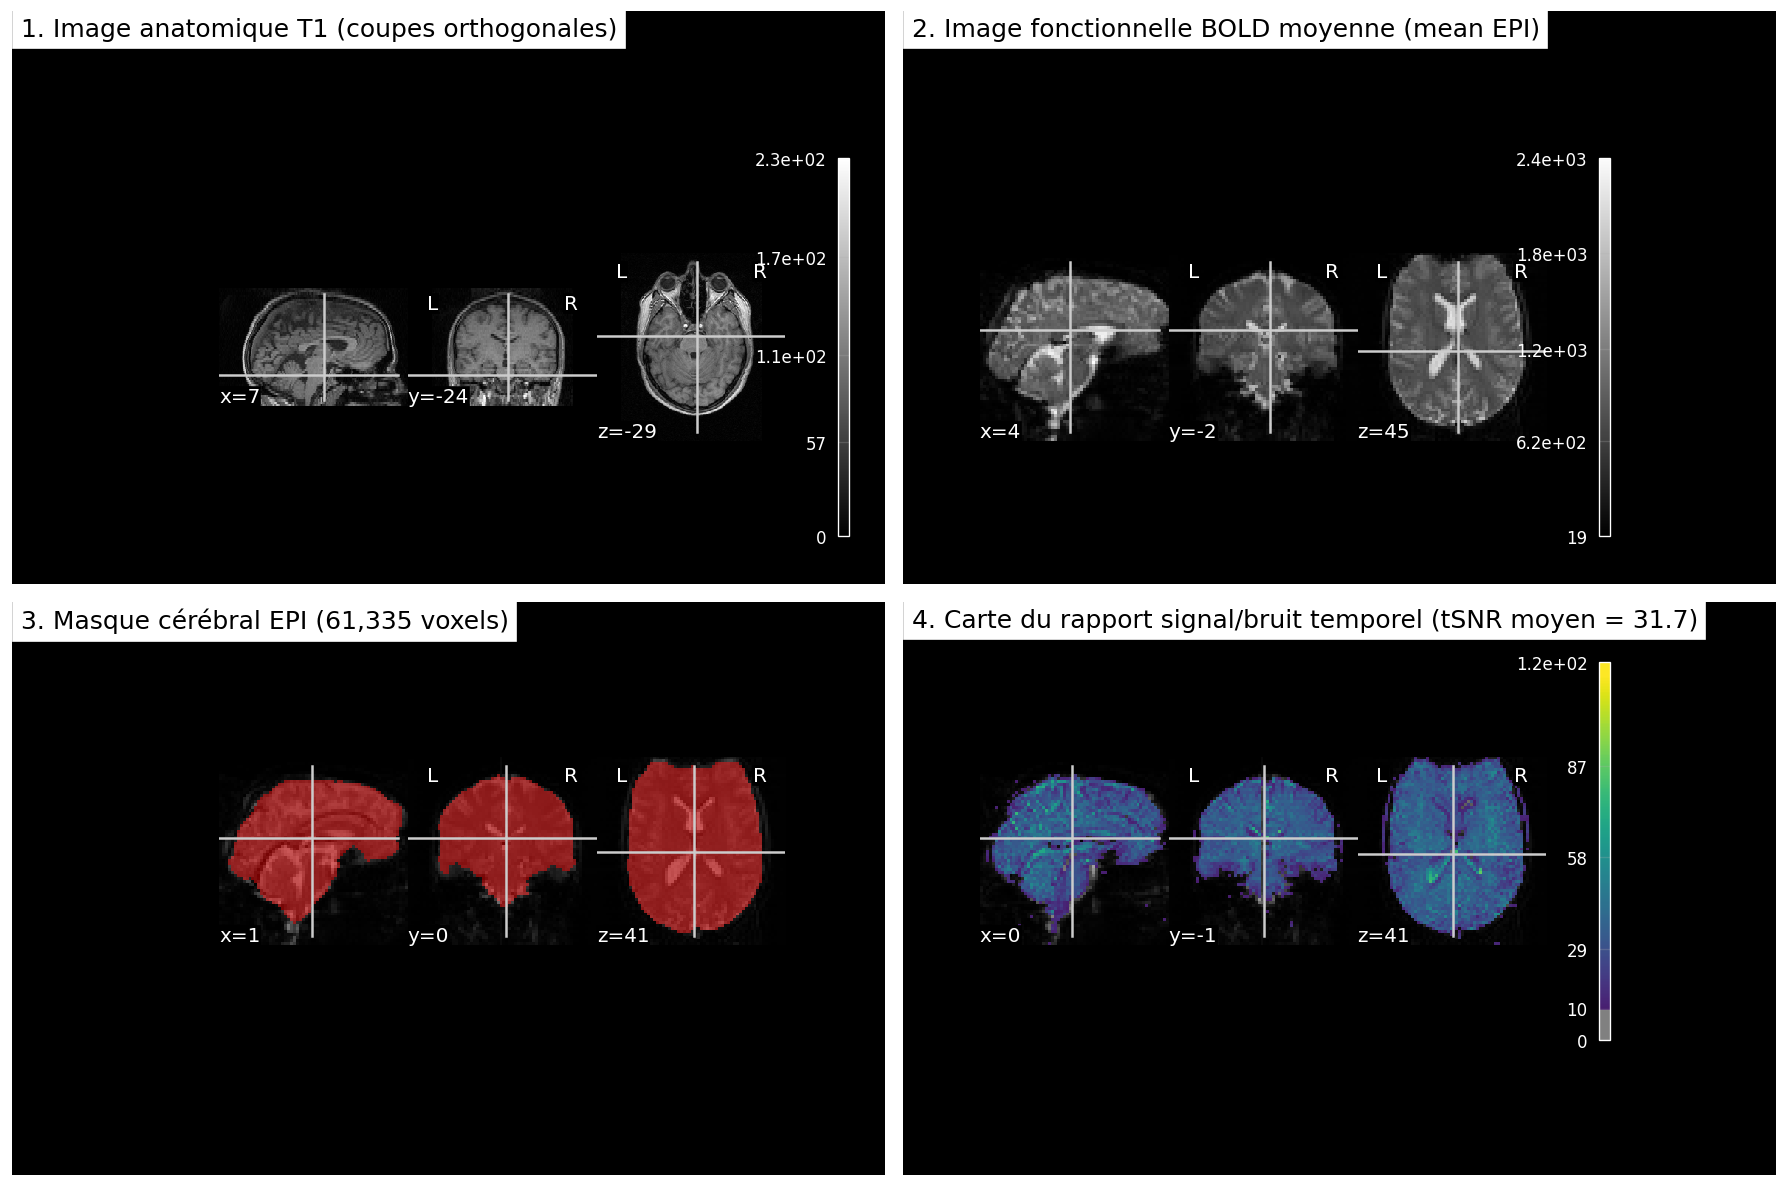

In [6]:
# 2.1 Calcul de l'image fonctionnelle moyenne, de l'écart-type temporel, du tSNR et du masque cérébral
mean_fmri_img = image.mean_img(fmri_img)
brain_mask_img = masking.compute_epi_mask(fmri_img)

fmri_data = fmri_img.get_fdata()
mask_data = brain_mask_img.get_fdata().astype(bool)

n_total_voxels = int(np.prod(func_shape[:3]))
n_brain_voxels = int(mask_data.sum())
brain_volume_cm3 = (n_brain_voxels * voxel_volume_mm3) / 1000.0

# Calcul de la carte tSNR
temporal_mean = fmri_data.mean(axis=-1)
temporal_std = fmri_data.std(axis=-1, ddof=1)
with np.errstate(divide="ignore", invalid="ignore"):
    tsnr_data = np.where(temporal_std > 0, temporal_mean / temporal_std, 0.0)
tsnr_img = nib.Nifti1Image(tsnr_data, fmri_img.affine, fmri_img.header)
nib.save(tsnr_img, NIFTI_DIR / "tsnr_map.nii.gz")

mean_tsnr_brain = float(tsnr_data[mask_data].mean())
median_tsnr_brain = float(np.median(tsnr_data[mask_data]))

print(f"Nombre total de voxels dans la boîte 3D : {n_total_voxels:,}")
print(f"Nombre de voxels dans le masque cérébral : {n_brain_voxels:,} ({100*n_brain_voxels/n_total_voxels:.1f}% du volume total, soit {brain_volume_cm3:.1f} cm³)")
print(f"tSNR moyen intra-masque                 : {mean_tsnr_brain:.2f} (médiane : {median_tsnr_brain:.2f})")

# Visualisation des coupes anatomiques, fonctionnelles moyennes, du masque et du tSNR
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

plotting.plot_anat(
    anat_img,
    title="1. Image anatomique T1 (coupes orthogonales)",
    axes=axes[0, 0],
    display_mode="ortho",
    dim=-0.5,
)
plotting.plot_epi(
    mean_fmri_img,
    title="2. Image fonctionnelle BOLD moyenne (mean EPI)",
    axes=axes[0, 1],
    display_mode="ortho",
    colorbar=True,
)
plotting.plot_roi(
    brain_mask_img,
    bg_img=mean_fmri_img,
    title=f"3. Masque cérébral EPI ({n_brain_voxels:,} voxels)",
    axes=axes[1, 0],
    display_mode="ortho",
    cmap="autumn",
    alpha=0.45,
)
plotting.plot_stat_map(
    tsnr_img,
    bg_img=mean_fmri_img,
    title=f"4. Carte du rapport signal/bruit temporel (tSNR moyen = {mean_tsnr_brain:.1f})",
    axes=axes[1, 1],
    display_mode="ortho",
    cmap="viridis",
    threshold=10.0,
    colorbar=True,
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step2_spatial_qc_overview.png", bbox_inches="tight")
plt.show()

=== Résumé du Contrôle Qualité Temporel ===
Intensité moyenne intra-masque : 894.00 ± 4.67 (min=885.20, max=904.54)
Variation temporelle (PSC)     : de -0.984% à +1.179% (écart-type = 0.523%)
DVARS moyen (hors scan 0)      : 41.55 ± 4.61 (max = 51.93 au scan 48)
Pente de dérive linéaire       : -0.02527 unités/s (r = -0.923, p = 7.5601e-36)
Volumes atypiques (|Z| > 2.5) sur l'intensité moyenne : []
Volumes atypiques (|Z| > 2.5) sur le DVARS            : []


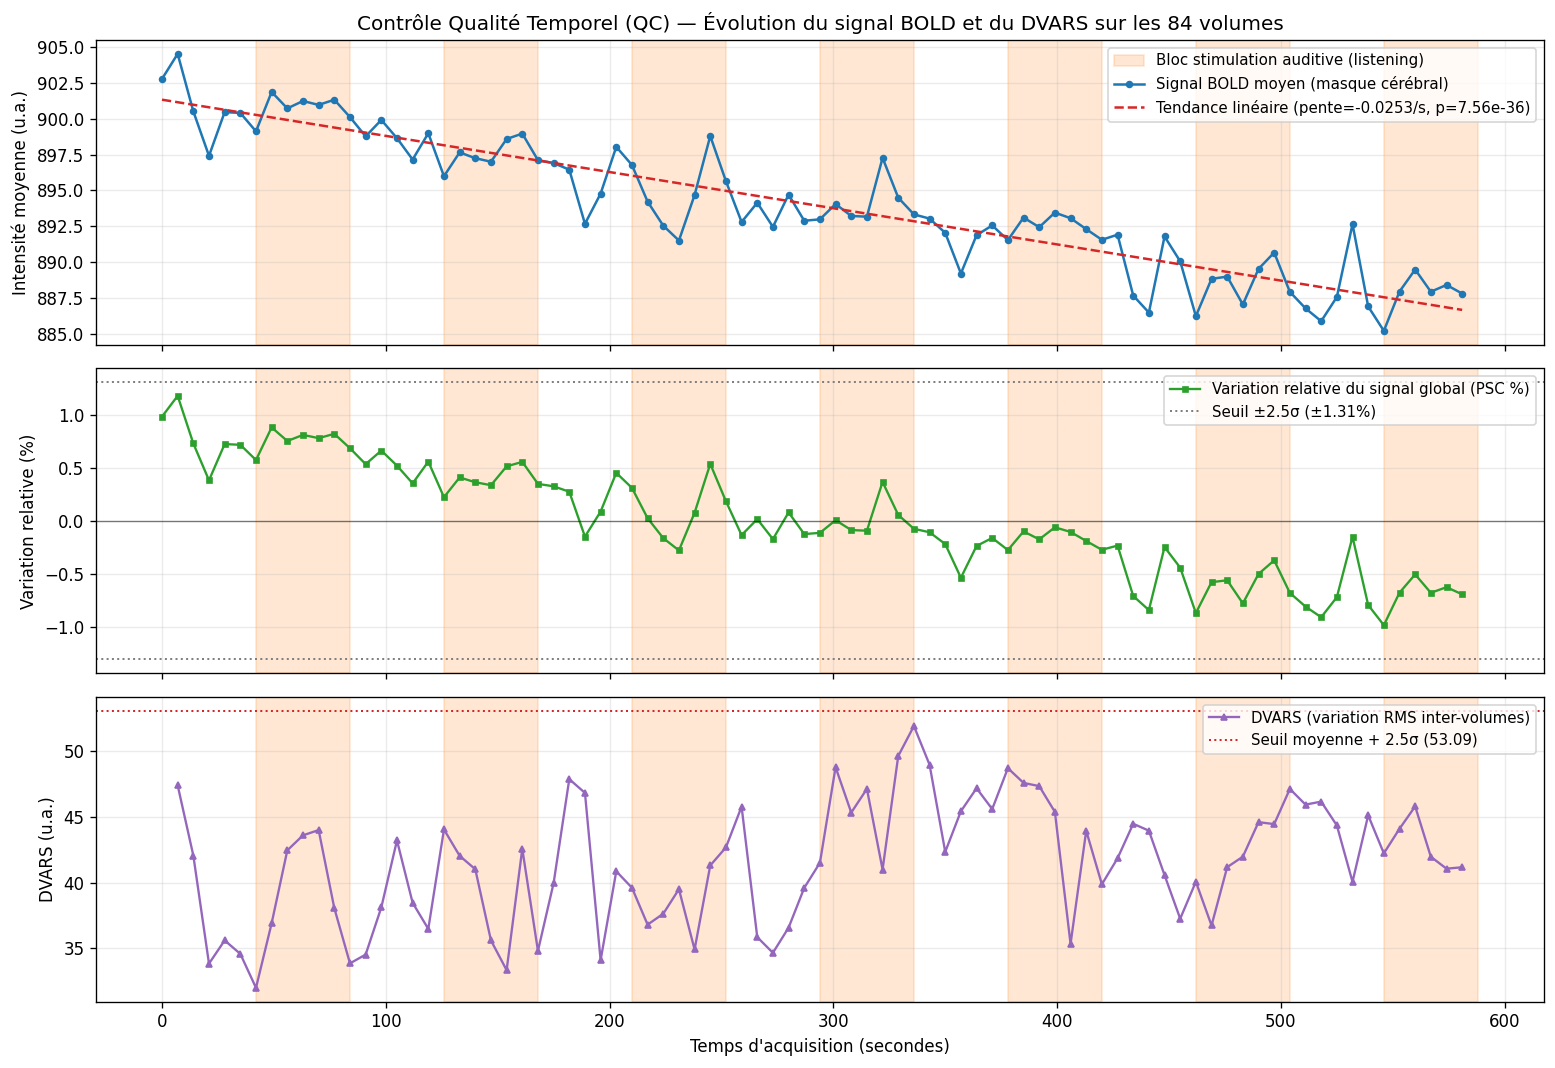

In [7]:
# 2.2 Analyse temporelle du signal BOLD et détection de variations inhabituelles
# Extraction des séries temporelles des voxels du masque (forme : n_scans x n_brain_voxels)
masked_timeseries = masking.apply_mask(fmri_img, brain_mask_img)

frame_indices = np.arange(n_scans)
frame_times = frame_indices * t_r

# Indicateurs temporels volume par volume
global_mean_signal = fmri_data.reshape(-1, n_scans).mean(axis=0)
brain_mean_signal = masked_timeseries.mean(axis=1)
brain_std_signal = masked_timeseries.std(axis=1)

# Signal normalisé en pourcentage de variation par rapport à la moyenne temporelle (PSC : Percent Signal Change)
brain_psc_signal = 100.0 * (brain_mean_signal - brain_mean_signal.mean()) / brain_mean_signal.mean()

# Calcul du DVARS (Derivative of RMS variance over voxels)
diff_timeseries = np.diff(masked_timeseries, axis=0)
dvars = np.zeros(n_scans)
dvars[1:] = np.sqrt(np.mean(diff_timeseries ** 2, axis=1))

# Détection statistique des volumes atypiques (au-delà de +/- 2.5 écarts-types sur le signal moyen ou DVARS)
z_brain_mean = stats.zscore(brain_mean_signal)
z_dvars = stats.zscore(dvars[1:])
outlier_scans_mean = frame_indices[np.abs(z_brain_mean) > 2.5]
outlier_scans_dvars = frame_indices[1:][np.abs(z_dvars) > 2.5]

# Construction du tableau de contrôle qualité temporel
qc_temporal_df = pd.DataFrame({
    "scan_index": frame_indices,
    "time_s": frame_times,
    "global_mean_intensity": global_mean_signal,
    "brain_mean_intensity": brain_mean_signal,
    "brain_spatial_std": brain_std_signal,
    "brain_psc_percent": brain_psc_signal,
    "dvars": dvars,
    "z_score_brain_mean": z_brain_mean,
})
qc_temporal_df.to_csv(TABLES_DIR / "qc_temporal_metrics.csv", index=False)

# Tendance linéaire sur le signal moyen cérébral (évaluation de la dérive temporelle)
slope, intercept, r_val, p_val_drift, std_err = stats.linregress(frame_times, brain_mean_signal)

print("=== Résumé du Contrôle Qualité Temporel ===")
print(f"Intensité moyenne intra-masque : {brain_mean_signal.mean():.2f} ± {brain_mean_signal.std(ddof=1):.2f} (min={brain_mean_signal.min():.2f}, max={brain_mean_signal.max():.2f})")
print(f"Variation temporelle (PSC)     : de {brain_psc_signal.min():.3f}% à +{brain_psc_signal.max():.3f}% (écart-type = {brain_psc_signal.std(ddof=1):.3f}%)")
print(f"DVARS moyen (hors scan 0)      : {dvars[1:].mean():.2f} ± {dvars[1:].std(ddof=1):.2f} (max = {dvars[1:].max():.2f} au scan {int(np.argmax(dvars))})")
print(f"Pente de dérive linéaire       : {slope:.5f} unités/s (r = {r_val:.3f}, p = {p_val_drift:.4e})")
print(f"Volumes atypiques (|Z| > 2.5) sur l'intensité moyenne : {outlier_scans_mean.tolist()}")
print(f"Volumes atypiques (|Z| > 2.5) sur le DVARS            : {outlier_scans_dvars.tolist()}")

# Graphique de contrôle qualité temporel multi-panneaux
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

# Fonction utilitaire pour ombrer les blocs d'écoute ("listening")
def shade_active_blocks(ax, label_first=True):
    first = True
    for _, row in events_df.iterrows():
        ax.axvspan(
            row["onset"],
            row["onset"] + row["duration"],
            color="#ff7f0e",
            alpha=0.18,
            label=f"Bloc stimulation auditive ({active_condition_name})" if (first and label_first) else None,
        )
        first = False

# Panneau 1 : Intensité moyenne intra-masque et droite de dérive
shade_active_blocks(axes[0], label_first=True)
axes[0].plot(frame_times, brain_mean_signal, color="#1f77b4", marker="o", markersize=3.5, lw=1.5, label="Signal BOLD moyen (masque cérébral)")
axes[0].plot(frame_times, intercept + slope * frame_times, color="#d62728", ls="--", lw=1.5, label=f"Tendance linéaire (pente={slope:.4f}/s, p={p_val_drift:.2e})")
if len(outlier_scans_mean) > 0:
    axes[0].scatter(frame_times[outlier_scans_mean], brain_mean_signal[outlier_scans_mean], color="red", s=60, zorder=5, label="Scan atypique (|Z| > 2.5)")
axes[0].set_ylabel("Intensité moyenne (u.a.)")
axes[0].set_title(f"Contrôle Qualité Temporel (QC) — Évolution du signal BOLD et du DVARS sur les {n_scans} volumes")
axes[0].legend(loc="upper right", fontsize=9)

# Panneau 2 : Pourcentage de variation du signal (PSC) et seuils +/- 2.5 sigma
shade_active_blocks(axes[1], label_first=False)
axes[1].plot(frame_times, brain_psc_signal, color="#2ca02c", marker="s", markersize=3, lw=1.4, label="Variation relative du signal global (PSC %)")
psc_thresh = 2.5 * brain_psc_signal.std(ddof=1)
axes[1].axhline(psc_thresh, color="gray", ls=":", lw=1.2, label=f"Seuil ±2.5σ (±{psc_thresh:.2f}%)")
axes[1].axhline(-psc_thresh, color="gray", ls=":", lw=1.2)
axes[1].axhline(0.0, color="black", lw=0.8, alpha=0.5)
axes[1].set_ylabel("Variation relative (%)")
axes[1].legend(loc="upper right", fontsize=9)

# Panneau 3 : DVARS
shade_active_blocks(axes[2], label_first=False)
axes[2].plot(frame_times[1:], dvars[1:], color="#9467bd", marker="^", markersize=3.5, lw=1.4, label="DVARS (variation RMS inter-volumes)")
dvars_thresh = dvars[1:].mean() + 2.5 * dvars[1:].std(ddof=1)
axes[2].axhline(dvars_thresh, color="#d62728", ls=":", lw=1.2, label=f"Seuil moyenne + 2.5σ ({dvars_thresh:.2f})")
if len(outlier_scans_dvars) > 0:
    axes[2].scatter(frame_times[outlier_scans_dvars], dvars[outlier_scans_dvars], color="red", s=60, zorder=5, label="Pic DVARS (|Z| > 2.5)")
axes[2].set_xlabel("Temps d'acquisition (secondes)")
axes[2].set_ylabel("DVARS (u.a.)")
axes[2].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step2_temporal_qc_timeseries.png", bbox_inches="tight")
plt.show()

---
## 5. Étape 3 — Modélisation du protocole expérimental et Matrice de Design

### Principe de la modélisation hémodynamique
L'activité neuronale déclenchée par la stimulation auditive consomme localement de l'oxygène, entraînant avec un léger retard une augmentation surcompensatoire du débit sanguin cérébral local : c'est l'effet **BOLD** (*Blood-Oxygen-Level Dependent*). La relation entre le créneau de stimulation neuronale $u(t)$ et la réponse hémodynamique attendue $x(t)$ est modélisée par une **convolution linéaire** avec la **Fonction de Réponse Hémodynamique canonique (HRF)** $h(t)$ :

$$x(t) = (u * h)(t) = \int_0^t u(\tau) \, h(t - \tau) \, d\tau$$

La HRF canonique de SPM est la différence de deux fonctions Gamma :
* Un **pic positif** principal autour de $t \approx 5\text{–}6\text{ s}$ après le début de la stimulation ;
* Un **undershoot post-stimulus** autour de $t \approx 15\text{–}20\text{ s}$ avant le retour à la ligne de base.

### Construction de la matrice de design $X$
Le fichier d'événements décrit les périodes de stimulation auditive (`listening`), tandis que les périodes de repos constituent la **ligne de base implicite**. Nous construisons la matrice de design complète intégrant :
* Le régresseur hémodynamique de la condition d'écoute (`listening`) convolué avec la HRF canonique `'spm'` ;
* Les régresseurs de **dérive temporelle basses fréquences** (*cosine drift* avec fréquence de coupure `high_pass = 0.01 Hz`, soit une période maximale de $100\text{ s}$) ;
* Le terme constant (`constant`) modélisant le niveau moyen du signal BOLD (ligne de base implicite).

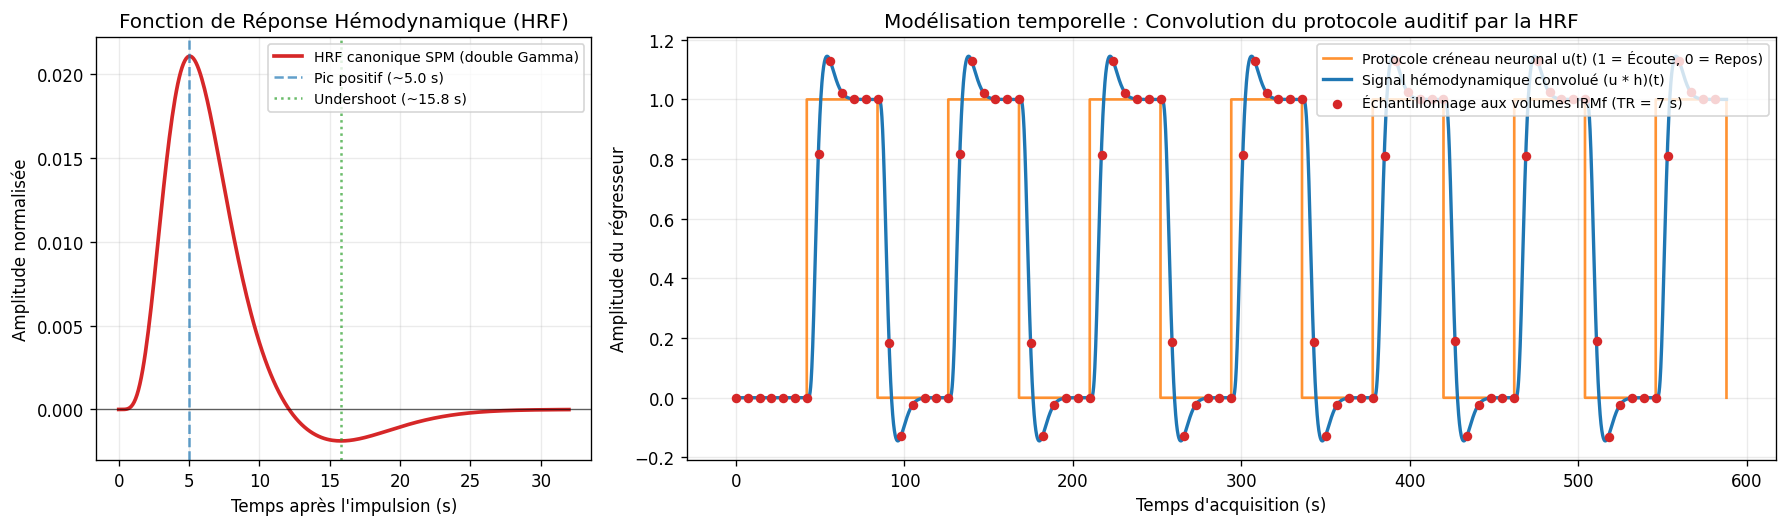

In [8]:
# 3.1 Illustration de la fonction HRF canonique et de la convolution du protocole auditif
# Grille temporelle fine (pas de 0.1 s) pour visualiser le signal boîte (boxcar) et la convolution HRF
fine_times = np.linspace(0, total_protocol_duration, int(total_protocol_duration * 10) + 1)
boxcar_signal = np.zeros_like(fine_times)
for _, row in events_df.iterrows():
    mask_t = (fine_times >= row["onset"]) & (fine_times < row["onset"] + row["duration"])
    boxcar_signal[mask_t] = 1.0

# Calcul du régresseur convolué avec la HRF canonique SPM (échantillonné aux temps d'acquisition TR = 7s)
convolved_reg_scans, _ = compute_regressor(
    exp_condition=(
        events_df["onset"].values,
        events_df["duration"].values,
        np.ones(len(events_df)),
    ),
    hrf_model="spm",
    frame_times=frame_times,
)

# Calcul sur la grille fine pour visualisation continue
convolved_reg_fine, _ = compute_regressor(
    exp_condition=(
        events_df["onset"].values,
        events_df["duration"].values,
        np.ones(len(events_df)),
    ),
    hrf_model="spm",
    frame_times=fine_times,
)

# Impulsion unique de 0.1s pour illustrer la forme de la HRF canonique SPM sur 32 secondes
hrf_time = np.linspace(0, 32, 321)
hrf_impulse, _ = compute_regressor(
    exp_condition=(np.array([0.0]), np.array([0.1]), np.array([1.0])),
    hrf_model="spm",
    frame_times=hrf_time,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})

# Gauche : Réponse impulsionnelle HRF canonique
axes[0].plot(hrf_time, hrf_impulse[:, 0], color="#d62728", lw=2.2, label="HRF canonique SPM (double Gamma)")
axes[0].axhline(0, color="black", lw=0.8, alpha=0.6)
peak_t = hrf_time[np.argmax(hrf_impulse[:, 0])]
undershoot_t = hrf_time[np.argmin(hrf_impulse[:, 0])]
axes[0].axvline(peak_t, color="#1f77b4", ls="--", alpha=0.7, label=f"Pic positif (~{peak_t:.1f} s)")
axes[0].axvline(undershoot_t, color="#2ca02c", ls=":", alpha=0.7, label=f"Undershoot (~{undershoot_t:.1f} s)")
axes[0].set_title("Fonction de Réponse Hémodynamique (HRF)")
axes[0].set_xlabel("Temps après l'impulsion (s)")
axes[0].set_ylabel("Amplitude normalisée")
axes[0].legend(loc="upper right", fontsize=8.5)

# Droite : Créneaux de stimulation (boxcar) vs régresseur BOLD prédit (convolué)
axes[1].step(fine_times, boxcar_signal, where="post", color="#ff7f0e", lw=1.6, alpha=0.85, label="Protocole créneau neuronal u(t) (1 = Écoute, 0 = Repos)")
axes[1].plot(fine_times, convolved_reg_fine[:, 0], color="#1f77b4", lw=2.0, label="Signal hémodynamique convolué (u * h)(t)")
axes[1].scatter(frame_times, convolved_reg_scans[:, 0], color="#d62728", s=22, zorder=5, label=f"Échantillonnage aux volumes IRMf (TR = {t_r:.0f} s)")
axes[1].set_title("Modélisation temporelle : Convolution du protocole auditif par la HRF")
axes[1].set_xlabel("Temps d'acquisition (s)")
axes[1].set_ylabel("Amplitude du régresseur")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step3_hrf_convolution_protocol.png", bbox_inches="tight")
plt.show()

=== Caractéristiques de la Matrice de Design X ===
Dimensions de la matrice X (N_scans x P_régresseurs) : (84, 13)
Colonnes de la matrice de design : ['listening', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'drift_5', 'drift_6', 'drift_7', 'drift_8', 'drift_9', 'drift_10', 'drift_11', 'constant']
Nombre de régresseurs de dérive (Cosine Drift <= 0.01 Hz) : 11
Degrés de liberté résiduels (N - P) : 71
Conditionnement numérique cond(X) : 11.20


,listening,drift_1,drift_2,drift_3,drift_4,drift_5,drift_6,drift_7,drift_8,drift_9,drift_10,drift_11,constant
0.0,0.0000,0.1543,0.1542,0.1541,0.1539,0.1536,0.1533,0.1530,0.1526,0.1521,0.1516,0.1511,1.0
7.0,0.0000,0.1541,0.1533,0.1521,0.1504,0.1483,0.1456,0.1426,0.1390,0.1350,0.1307,0.1258,1.0
14.0,0.0000,0.1536,0.1516,0.1483,0.1436,0.1377,0.1307,0.1224,0.1131,0.1028,0.0916,0.0796,1.0
21.0,0.0000,0.1530,0.1490,0.1426,0.1336,0.1224,0.1091,0.0939,0.0772,0.0590,0.0399,0.0201,1.0
28.0,0.0000,0.1521,0.1456,0.1350,0.1206,0.1028,0.0821,0.0590,0.0343,0.0087,-0.0173,-0.0427,1.0
35.0,0.0000,0.1511,0.1414,0.1258,0.1050,0.0796,0.0510,0.0201,-0.0115,-0.0427,-0.0721,-0.0984,1.0
42.0,0.0000,0.1498,0.1364,0.1151,0.0869,0.0537,0.0173,-0.0201,-0.0564,-0.0893,-0.1170,-0.1377,1.0
49.0,0.8171,0.1483,0.1307,0.1028,0.0669,0.0258,-0.0173,-0.0590,-0.0962,-0.1258,-0.1456,-0.1541,1.0
56.0,1.1292,0.1466,0.1242,0.0893,0.0455,-0.0029,-0.0510,-0.0939,-0.1275,-0.1483,-0.1542,-0.1447,1.0
63.0,1.0229,0.1447,0.1170,0.0746,0.0230,-0.0315,-0.0821,-0.1224,-0.1474,-0.1541,-0.1414,-0.1111,1.0


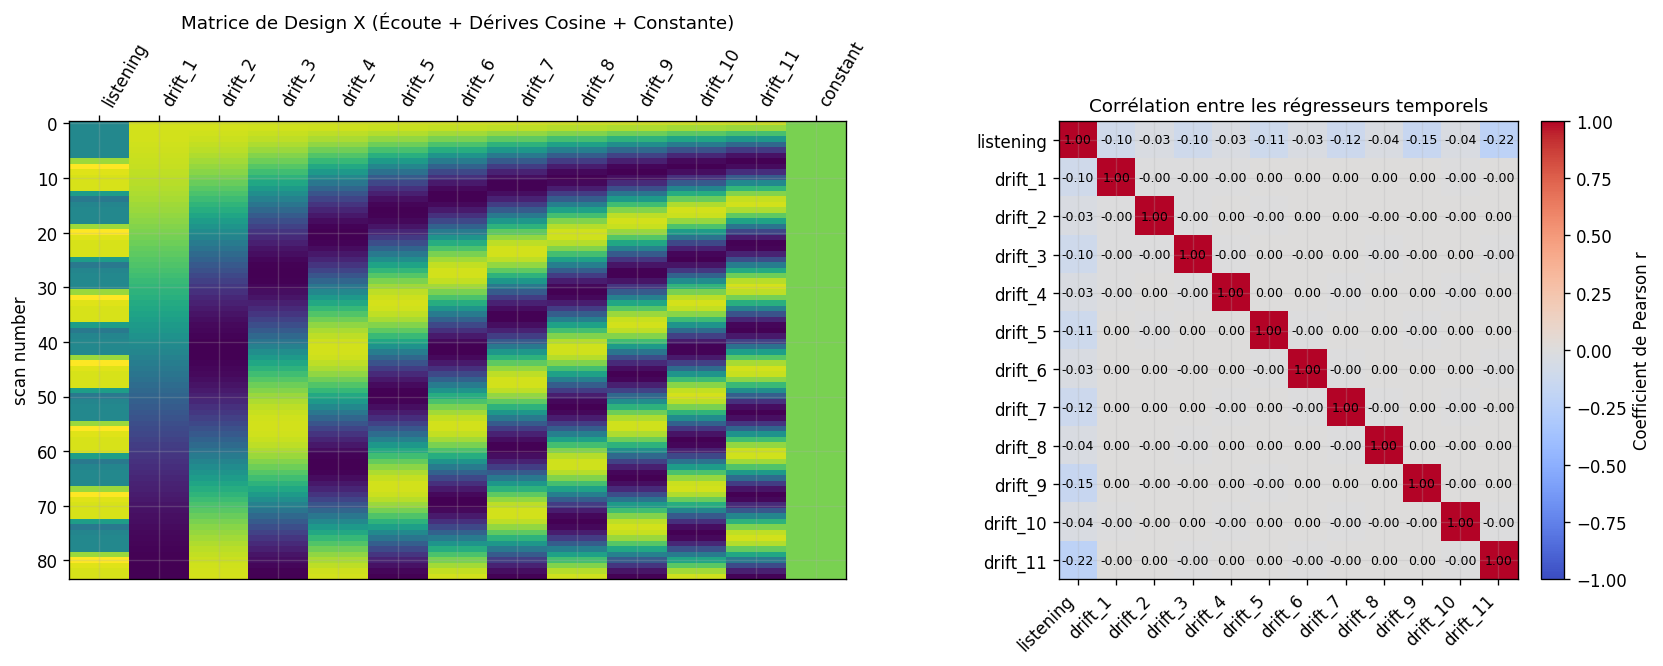

In [9]:
# 3.2 Création et inspection de la matrice de design X
design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events_df,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01,
)

# Sauvegarde de la matrice de design au format CSV
design_matrix.to_csv(TABLES_DIR / "design_matrix.csv", index=True)

n_regressors = design_matrix.shape[1]
drift_cols = [c for c in design_matrix.columns if c.startswith("drift_")]
cond_number = float(np.linalg.cond(design_matrix.values))

print("=== Caractéristiques de la Matrice de Design X ===")
print(f"Dimensions de la matrice X (N_scans x P_régresseurs) : {design_matrix.shape}")
print(f"Colonnes de la matrice de design : {list(design_matrix.columns)}")
print(f"Nombre de régresseurs de dérive (Cosine Drift <= 0.01 Hz) : {len(drift_cols)}")
print(f"Degrés de liberté résiduels (N - P) : {n_scans - n_regressors}")
print(f"Conditionnement numérique cond(X) : {cond_number:.2f}")

display(design_matrix.head(10).round(4))

# Visualisation de la matrice de design et de la matrice de corrélation des régresseurs
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

plotting.plot_design_matrix(design_matrix, axes=axes[0])
axes[0].set_title("Matrice de Design X (Écoute + Dérives Cosine + Constante)", fontsize=11)

# Corrélation entre les régresseurs (hors constante dont la variance est nulle)
non_const_cols = [c for c in design_matrix.columns if c != "constant"]
corr_matrix = design_matrix[non_const_cols].corr()
im = axes[1].imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(non_const_cols)))
axes[1].set_yticks(range(len(non_const_cols)))
axes[1].set_xticklabels(non_const_cols, rotation=45, ha="right")
axes[1].set_yticklabels(non_const_cols)
axes[1].set_title("Corrélation entre les régresseurs temporels", fontsize=11)
for i in range(len(non_const_cols)):
    for j in range(len(non_const_cols)):
        axes[1].text(j, i, f"{corr_matrix.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="black")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="Coefficient de Pearson r")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step3_design_matrix_and_correlations.png", bbox_inches="tight")
plt.show()

---
## 6. Étape 4 — Ajustement du Modèle Linéaire Général (GLM)

### Formulation mathématique
Pour chaque voxel $v \in \{1, \dots, V_{\text{mask}}\}$, la série temporelle du signal BOLD mesuré $Y_v \in \mathbb{R}^{T \times 1}$ est modélisée par l'équation linéaire :

$$Y_v = X \beta_v + \varepsilon_v$$

où :
* $Y_v$ est le vecteur colonne des $T$ observations temporelles du signal BOLD dans le voxel $v$ ;
* $X \in \mathbb{R}^{T \times P}$ est la matrice de design identique pour tous les voxels ;
* $\beta_v \in \mathbb{R}^{P \times 1}$ est le vecteur des paramètres (coefficients de régression) à estimer pour le voxel $v$ ;
* $\varepsilon_v \sim \mathcal{N}(0, \sigma_v^2 V_v)$ représente les résidus du modèle.

En IRMf, les observations successives ne sont pas temporellement indépendantes en raison de la lenteur hémodynamique et des fluctuations physiologiques. Nous utilisons donc `noise_model='ar1'` dans `FirstLevelModel`, ce qui modélise l'autocorrélation temporelle d'ordre 1 des résidus ($\varepsilon_{v,t} = \rho_v \varepsilon_{v,t-1} + \eta_{v,t}$) et applique un pré-blanchiment (*pre-whitening* par moindres carrés généralisés, GLS) avant l'estimation finale de $\hat{\beta}_v$.

/tmp/ipykernel_930/2249474245.py:14: RuntimeWarning: [MultiNiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  fmri_glm = fmri_glm.fit(fmri_img, design_matrices=design_matrix)


=== Ajustement du GLM terminé avec succès ===
Modèle de bruit temporel : ar1
Modèle HRF               : spm
Nombre de voxels ajustés : 61,335
R² moyen intra-masque    : 0.3950 (médiane = 0.3521, max = 0.9678)


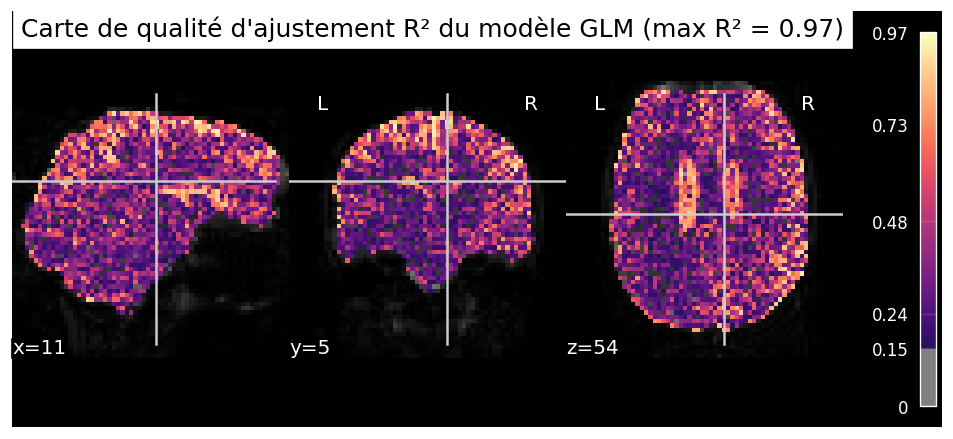

In [10]:
# 4.1 Instanciation et ajustement du FirstLevelModel avec autocorrélation AR(1)
fmri_glm = FirstLevelModel(
    t_r=t_r,
    noise_model="ar1",
    standardize=False,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01,
    mask_img=brain_mask_img,
    minimize_memory=False,
)

# Ajustement du GLM en fournissant directement notre matrice de design vérifiée
fmri_glm = fmri_glm.fit(fmri_img, design_matrices=design_matrix)

# Extraction de la carte R² (proportion de variance expliquée par le modèle complet)
r2_img = fmri_glm.r_square[0]
nib.save(r2_img, NIFTI_DIR / "r_square_map.nii.gz")
r2_values = masking.apply_mask(r2_img, brain_mask_img)

print("=== Ajustement du GLM terminé avec succès ===")
print(f"Modèle de bruit temporel : {fmri_glm.noise_model}")
print(f"Modèle HRF               : {fmri_glm.hrf_model}")
print(f"Nombre de voxels ajustés : {n_brain_voxels:,}")
print(f"R² moyen intra-masque    : {r2_values.mean():.4f} (médiane = {np.median(r2_values):.4f}, max = {r2_values.max():.4f})")

# Visualisation de la carte R² du modèle GLM
fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))
plotting.plot_stat_map(
    r2_img,
    bg_img=mean_fmri_img,
    title=f"Carte de qualité d'ajustement R² du modèle GLM (max R² = {r2_values.max():.2f})",
    axes=ax,
    display_mode="ortho",
    cmap="magma",
    threshold=0.15,
    colorbar=True,
)
plt.savefig(FIGURES_DIR / "step4_glm_rsquare_map.png", bbox_inches="tight")
plt.show()

---
## 7. Étape 5 — Calcul du contraste expérimental ($C = \text{Écoute} - \text{Ligne de base}$)

### Formulation du contraste et de la statistique de test
Le contraste étudié compare la condition d'écoute (`listening`) à la ligne de base implicite (repos) :

$$C = \text{Écoute} - \text{Ligne de base}$$

Dans notre matrice de design où la première colonne correspond au régresseur `listening` et où le repos constitue la ligne de base implicite, ce contraste s'écrit sous la forme du vecteur $c = [1, 0, \dots, 0]^T \in \mathbb{R}^{P \times 1}$.

Pour chaque voxel $v$, le GLM estime :
1. **La taille de l'effet (*Effect Size*)** : $\hat{\gamma}_v = c^T \hat{\beta}_v = \hat{\beta}_{v, \text{listening}}$ ;
2. **La variance de l'effet (*Effect Variance*)** : $\widehat{\text{Var}}(\hat{\gamma}_v) = \hat{\sigma}_v^2 \, c^T (X^T V_v^{-1} X)^{-1} c$ ;
3. **La statistique $t$ de Student** :
   $$t_v = \frac{c^T \hat{\beta}_v}{\sqrt{\widehat{\text{Var}}(\hat{\gamma}_v)}}$$
4. **Le score $Z$ équivalent** (transformation gaussienne quantile-quantile préservant la valeur-$p$ sous $H_0 : c^T \beta_v = 0$).

In [11]:
# 5.1 Définition du vecteur de contraste et calcul des cartes statistiques
contrast_matrix = np.zeros(design_matrix.shape[1])
contrast_matrix[0] = 1.0  # Colonne 'listening' vs ligne de base implicite ('rest')

print("Vecteur de contraste c :", dict(zip(design_matrix.columns, contrast_matrix)))

# Calcul de l'ensemble des cartes du contraste (z_score, stat, p_value, effect_size, effect_variance)
contrast_results = fmri_glm.compute_contrast(contrast_matrix, output_type="all")

z_map = contrast_results["z_score"]
t_map = contrast_results["stat"]
p_map = contrast_results["p_value"]
effect_size_map = contrast_results["effect_size"]
effect_var_map = contrast_results["effect_variance"]

# Sauvegarde immédiate des cartes NIfTI principales
nib.save(z_map, NIFTI_DIR / "z_map_listening_vs_baseline.nii.gz")
nib.save(t_map, NIFTI_DIR / "t_map_listening_vs_baseline.nii.gz")
nib.save(effect_size_map, NIFTI_DIR / "effect_size_listening_vs_baseline.nii.gz")
nib.save(effect_var_map, NIFTI_DIR / "effect_variance_listening_vs_baseline.nii.gz")

# Statistiques descriptives des cartes à l'intérieur du masque cérébral
z_vals = masking.apply_mask(z_map, brain_mask_img)
t_vals = masking.apply_mask(t_map, brain_mask_img)
eff_vals = masking.apply_mask(effect_size_map, brain_mask_img)

# Coordonnées MNI/monde du pic d'activation maximal
z_data_3d = z_map.get_fdata()
peak_voxel_idx = np.unravel_index(np.argmax(z_data_3d), z_data_3d.shape)
peak_world_coords = nib.affines.apply_affine(z_map.affine, peak_voxel_idx)

print("\n=== Résumé statistique du contraste (Écoute - Ligne de base) ===")
print(f"Score Z       : min = {z_vals.min():.3f}, médiane = {np.median(z_vals):.3f}, moyenne = {z_vals.mean():.3f}, max = {z_vals.max():.3f}")
print(f"Statistique t : min = {t_vals.min():.3f}, médiane = {np.median(t_vals):.3f}, moyenne = {t_vals.mean():.3f}, max = {t_vals.max():.3f}")
print(f"Taille d'effet: min = {eff_vals.min():.3f}, médiane = {np.median(eff_vals):.3f}, moyenne = {eff_vals.mean():.3f}, max = {eff_vals.max():.3f}")
print(f"Pic maximal Z : Z = {z_data_3d[peak_voxel_idx]:.3f} au voxel {peak_voxel_idx} -> coordonnées (x={peak_world_coords[0]:.1f}, y={peak_world_coords[1]:.1f}, z={peak_world_coords[2]:.1f}) mm")

Vecteur de contraste c : {'listening': np.float64(1.0), 'drift_1': np.float64(0.0), 'drift_2': np.float64(0.0), 'drift_3': np.float64(0.0), 'drift_4': np.float64(0.0), 'drift_5': np.float64(0.0), 'drift_6': np.float64(0.0), 'drift_7': np.float64(0.0), 'drift_8': np.float64(0.0), 'drift_9': np.float64(0.0), 'drift_10': np.float64(0.0), 'drift_11': np.float64(0.0), 'constant': np.float64(0.0)}

=== Résumé statistique du contraste (Écoute - Ligne de base) ===
Score Z       : min = -7.072, médiane = 0.202, moyenne = 0.217, max = 9.342
Statistique t : min = -8.560, médiane = 0.203, moyenne = 0.225, max = 13.176
Taille d'effet: min = -27.203, médiane = 0.116, moyenne = 0.144, max = 23.536
Pic maximal Z : Z = 9.342 au voxel (np.int64(51), np.int64(29), np.int64(36)) -> coordonnées (x=-60.0, y=-6.0, z=42.0) mm


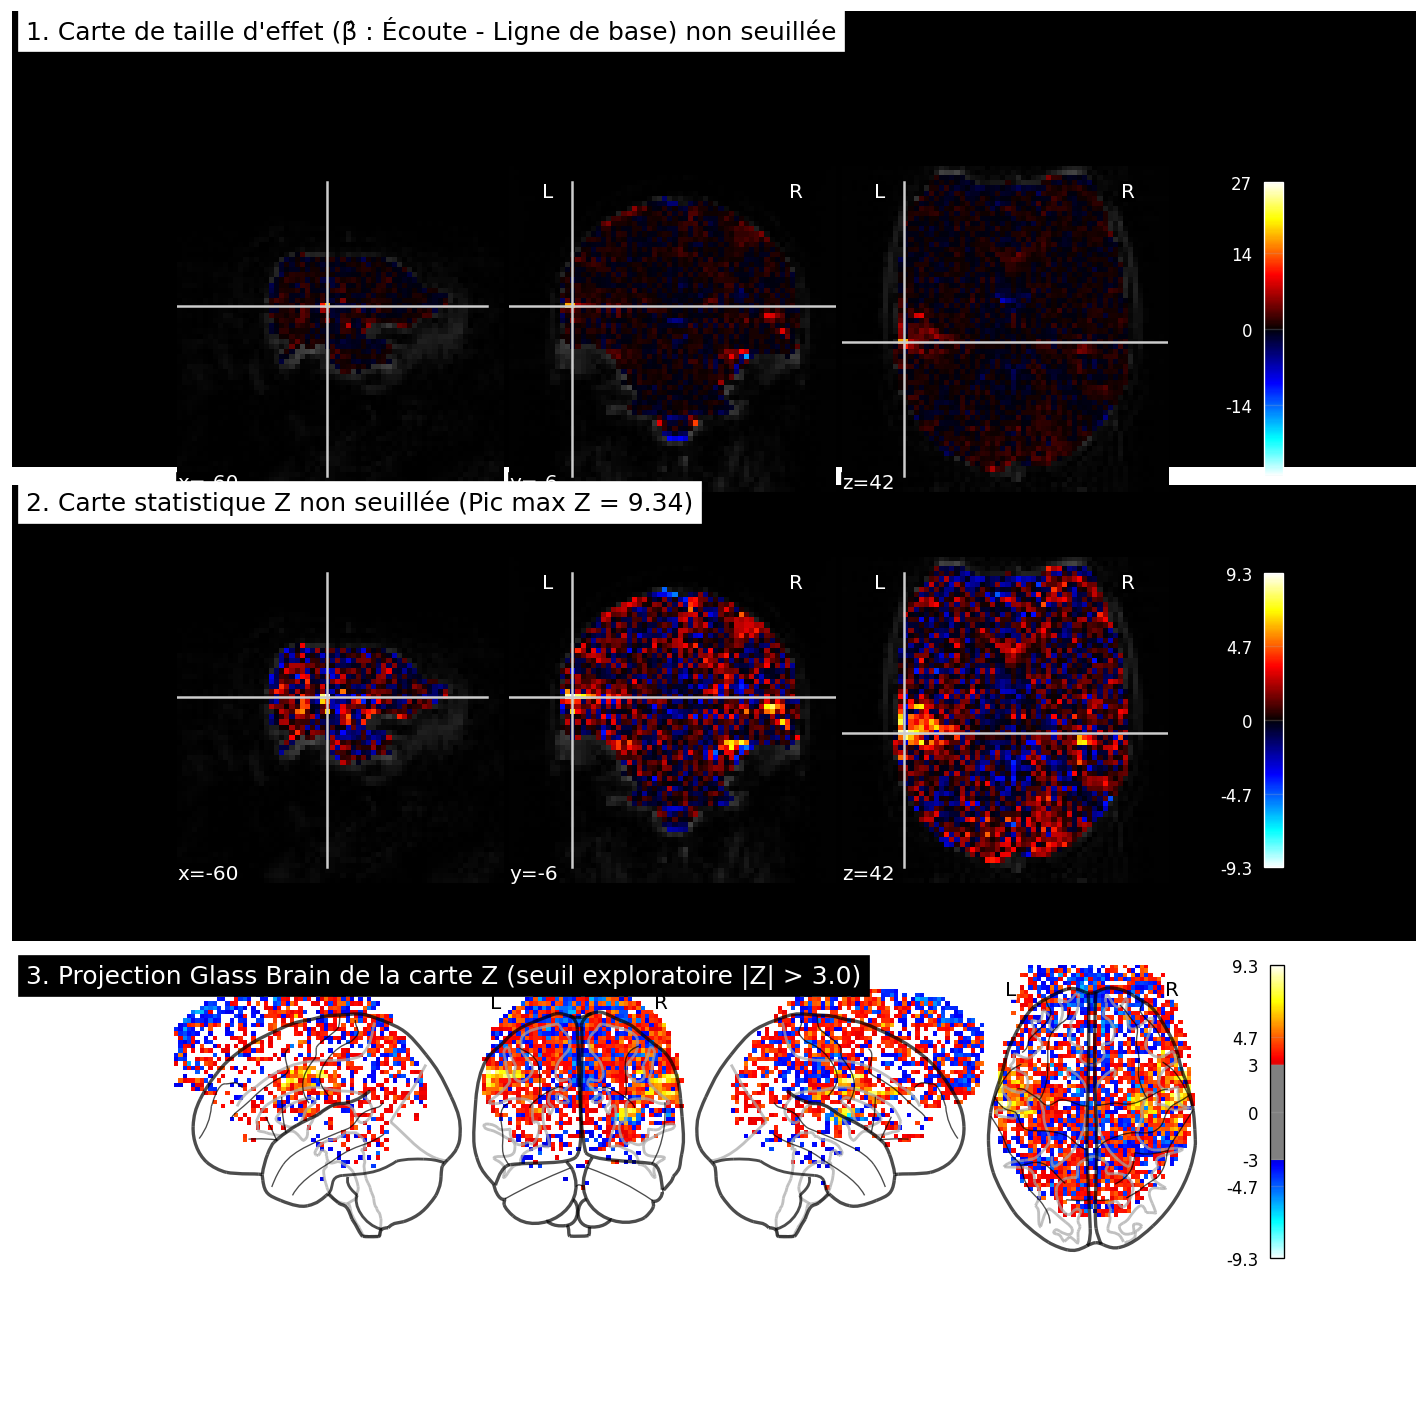

In [12]:
# 5.2 Visualisation de la carte d'effet (beta), de la carte Z non seuillée et de la vue Glass Brain
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

plotting.plot_stat_map(
    effect_size_map,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    title="1. Carte de taille d'effet (β̂ : Écoute - Ligne de base) non seuillée",
    axes=axes[0],
    display_mode="ortho",
    colorbar=True,
    cmap="cold_hot",
)

plotting.plot_stat_map(
    z_map,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    title=f"2. Carte statistique Z non seuillée (Pic max Z = {z_vals.max():.2f})",
    axes=axes[1],
    display_mode="ortho",
    colorbar=True,
    cmap="cold_hot",
)

plotting.plot_glass_brain(
    z_map,
    title="3. Projection Glass Brain de la carte Z (seuil exploratoire |Z| > 3.0)",
    axes=axes[2],
    display_mode="lyrz",
    colorbar=True,
    threshold=3.0,
    plot_abs=False,
    cmap="cold_hot",
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step5_effect_size_and_z_maps.png", bbox_inches="tight")
plt.show()

---
## 8. Étape 6 — Correction statistique pour comparaisons multiples et interprétation

### Pourquoi corriger pour les comparaisons multiples ?
Le modèle GLM est ajusté indépendamment sur chacun des $V_{\text{mask}}$ voxels du masque cérébral. Si l'on applique un seuil naïf non corrigé de $\alpha = 0.001$ sous l'hypothèse nulle globale, on s'attendrait par pur hasard à environ $0.001 \times V_{\text{mask}}$ faux positifs.

Nous comparons donc **quatre niveaux de seuillage** :
1. **Carte non seuillée** : distribution complète des scores $Z$ sur l'ensemble du cerveau ;
2. **Seuil non corrigé ($p < 0.001$, `height_control='fpr'`)** : contrôle du taux de faux positifs par voxel individuel ;
3. **Correction FDR (*False Discovery Rate*, Benjamini-Hochberg, $q < 0.05$, `height_control='fdr'`)** : contrôle la proportion attendue de faux positifs parmi les voxels déclarés actifs (avec un seuil d'étendue spatiale de `cluster_threshold = 10` voxels pour éliminer les voxels isolés) ;
4. **Correction de Bonferroni ($p_{\text{FWE}} < 0.05$, `height_control='bonferroni'`)** : contrôle strict du risque d'erreur par famille (*Family-Wise Error Rate*, FWER) sur tout le volume cérébral.

In [13]:
# 6.1 Application des corrections pour comparaisons multiples (FPR, FDR, Bonferroni)
# 1) Seuil non corrigé p < 0.001 (FPR)
z_map_fpr, thresh_fpr = threshold_stats_img(
    z_map, alpha=0.001, height_control="fpr", cluster_threshold=0, two_sided=True
)

# 2) Correction FDR (q < 0.05) sans filtre de taille de cluster puis avec cluster_threshold = 10 voxels
z_map_fdr_raw, thresh_fdr = threshold_stats_img(
    z_map, alpha=0.05, height_control="fdr", cluster_threshold=0, two_sided=True
)
z_map_fdr_cluster10, _ = threshold_stats_img(
    z_map, alpha=0.05, height_control="fdr", cluster_threshold=10, two_sided=True
)

# 3) Correction Bonferroni (p_FWE < 0.05) avec cluster_threshold = 10 voxels
z_map_bonf, thresh_bonf = threshold_stats_img(
    z_map, alpha=0.05, height_control="bonferroni", cluster_threshold=10, two_sided=True
)

# Sauvegarde des cartes corrigées au format NIfTI
nib.save(z_map_fdr_cluster10, NIFTI_DIR / "z_map_fdr_q005_cluster10.nii.gz")
nib.save(z_map_bonf, NIFTI_DIR / "z_map_bonferroni_p005_cluster10.nii.gz")

# Comptage exact des voxels survivant à chaque seuil
def count_active_voxels(stat_img):
    data = masking.apply_mask(stat_img, brain_mask_img)
    n_pos = int(np.sum(data > 0))
    n_neg = int(np.sum(data < 0))
    return n_pos + n_neg, n_pos, n_neg

n_tot_fpr, n_pos_fpr, n_neg_fpr = count_active_voxels(z_map_fpr)
n_tot_fdr0, n_pos_fdr0, n_neg_fdr0 = count_active_voxels(z_map_fdr_raw)
n_tot_fdr10, n_pos_fdr10, n_neg_fdr10 = count_active_voxels(z_map_fdr_cluster10)
n_tot_bonf, n_pos_bonf, n_neg_bonf = count_active_voxels(z_map_bonf)

threshold_comparison_df = pd.DataFrame([
    {
        "Méthode de seuillage": "Non corrigé (FPR, p < 0.001)",
        "Paramètre alpha / q": 0.001,
        "Taille min cluster (voxels)": 0,
        "Seuil critique |Z|": round(float(thresh_fpr), 3),
        "Voxels significatifs (total)": n_tot_fpr,
        "Voxels activés (Z > 0)": n_pos_fpr,
        "Voxels désactivés (Z < 0)": n_neg_fpr,
        "% du masque cérébral": round(100.0 * n_tot_fpr / n_brain_voxels, 2),
    },
    {
        "Méthode de seuillage": "FDR (Benjamini-Hochberg, q < 0.05)",
        "Paramètre alpha / q": 0.05,
        "Taille min cluster (voxels)": 0,
        "Seuil critique |Z|": round(float(thresh_fdr), 3),
        "Voxels significatifs (total)": n_tot_fdr0,
        "Voxels activés (Z > 0)": n_pos_fdr0,
        "Voxels désactivés (Z < 0)": n_neg_fdr0,
        "% du masque cérébral": round(100.0 * n_tot_fdr0 / n_brain_voxels, 2),
    },
    {
        "Méthode de seuillage": "FDR (q < 0.05) + Cluster >= 10 voxels",
        "Paramètre alpha / q": 0.05,
        "Taille min cluster (voxels)": 10,
        "Seuil critique |Z|": round(float(thresh_fdr), 3),
        "Voxels significatifs (total)": n_tot_fdr10,
        "Voxels activés (Z > 0)": n_pos_fdr10,
        "Voxels désactivés (Z < 0)": n_neg_fdr10,
        "% du masque cérébral": round(100.0 * n_tot_fdr10 / n_brain_voxels, 2),
    },
    {
        "Méthode de seuillage": "Bonferroni (FWER, p < 0.05) + Cluster >= 10",
        "Paramètre alpha / q": 0.05,
        "Taille min cluster (voxels)": 10,
        "Seuil critique |Z|": round(float(thresh_bonf), 3),
        "Voxels significatifs (total)": n_tot_bonf,
        "Voxels activés (Z > 0)": n_pos_bonf,
        "Voxels désactivés (Z < 0)": n_neg_bonf,
        "% du masque cérébral": round(100.0 * n_tot_bonf / n_brain_voxels, 2),
    },
])

threshold_comparison_df.to_csv(TABLES_DIR / "threshold_comparison_summary.csv", index=False)
print("=== Comparaison quantitative des méthodes de seuillage statistique ===")
display(threshold_comparison_df)

=== Comparaison quantitative des méthodes de seuillage statistique ===


,Méthode de seuillage,Paramètre alpha / q,Taille min cluster (voxels),Seuil critique |Z|,Voxels significatifs (total),Voxels activés (Z > 0),Voxels désactivés (Z < 0),% du masque cérébral
0,"Non corrigé (FPR, p < 0.001)",0.001,0,3.291,2407,1564,843,3.92
1,"FDR (Benjamini-Hochberg, q < 0.05)",0.050,0,2.960,3779,2479,1300,6.16
2,FDR (q < 0.05) + Cluster >= 10 voxels,0.050,10,2.960,576,509,67,0.94
3,"Bonferroni (FWER, p < 0.05) + Cluster >= 10",0.050,10,4.932,76,76,0,0.12


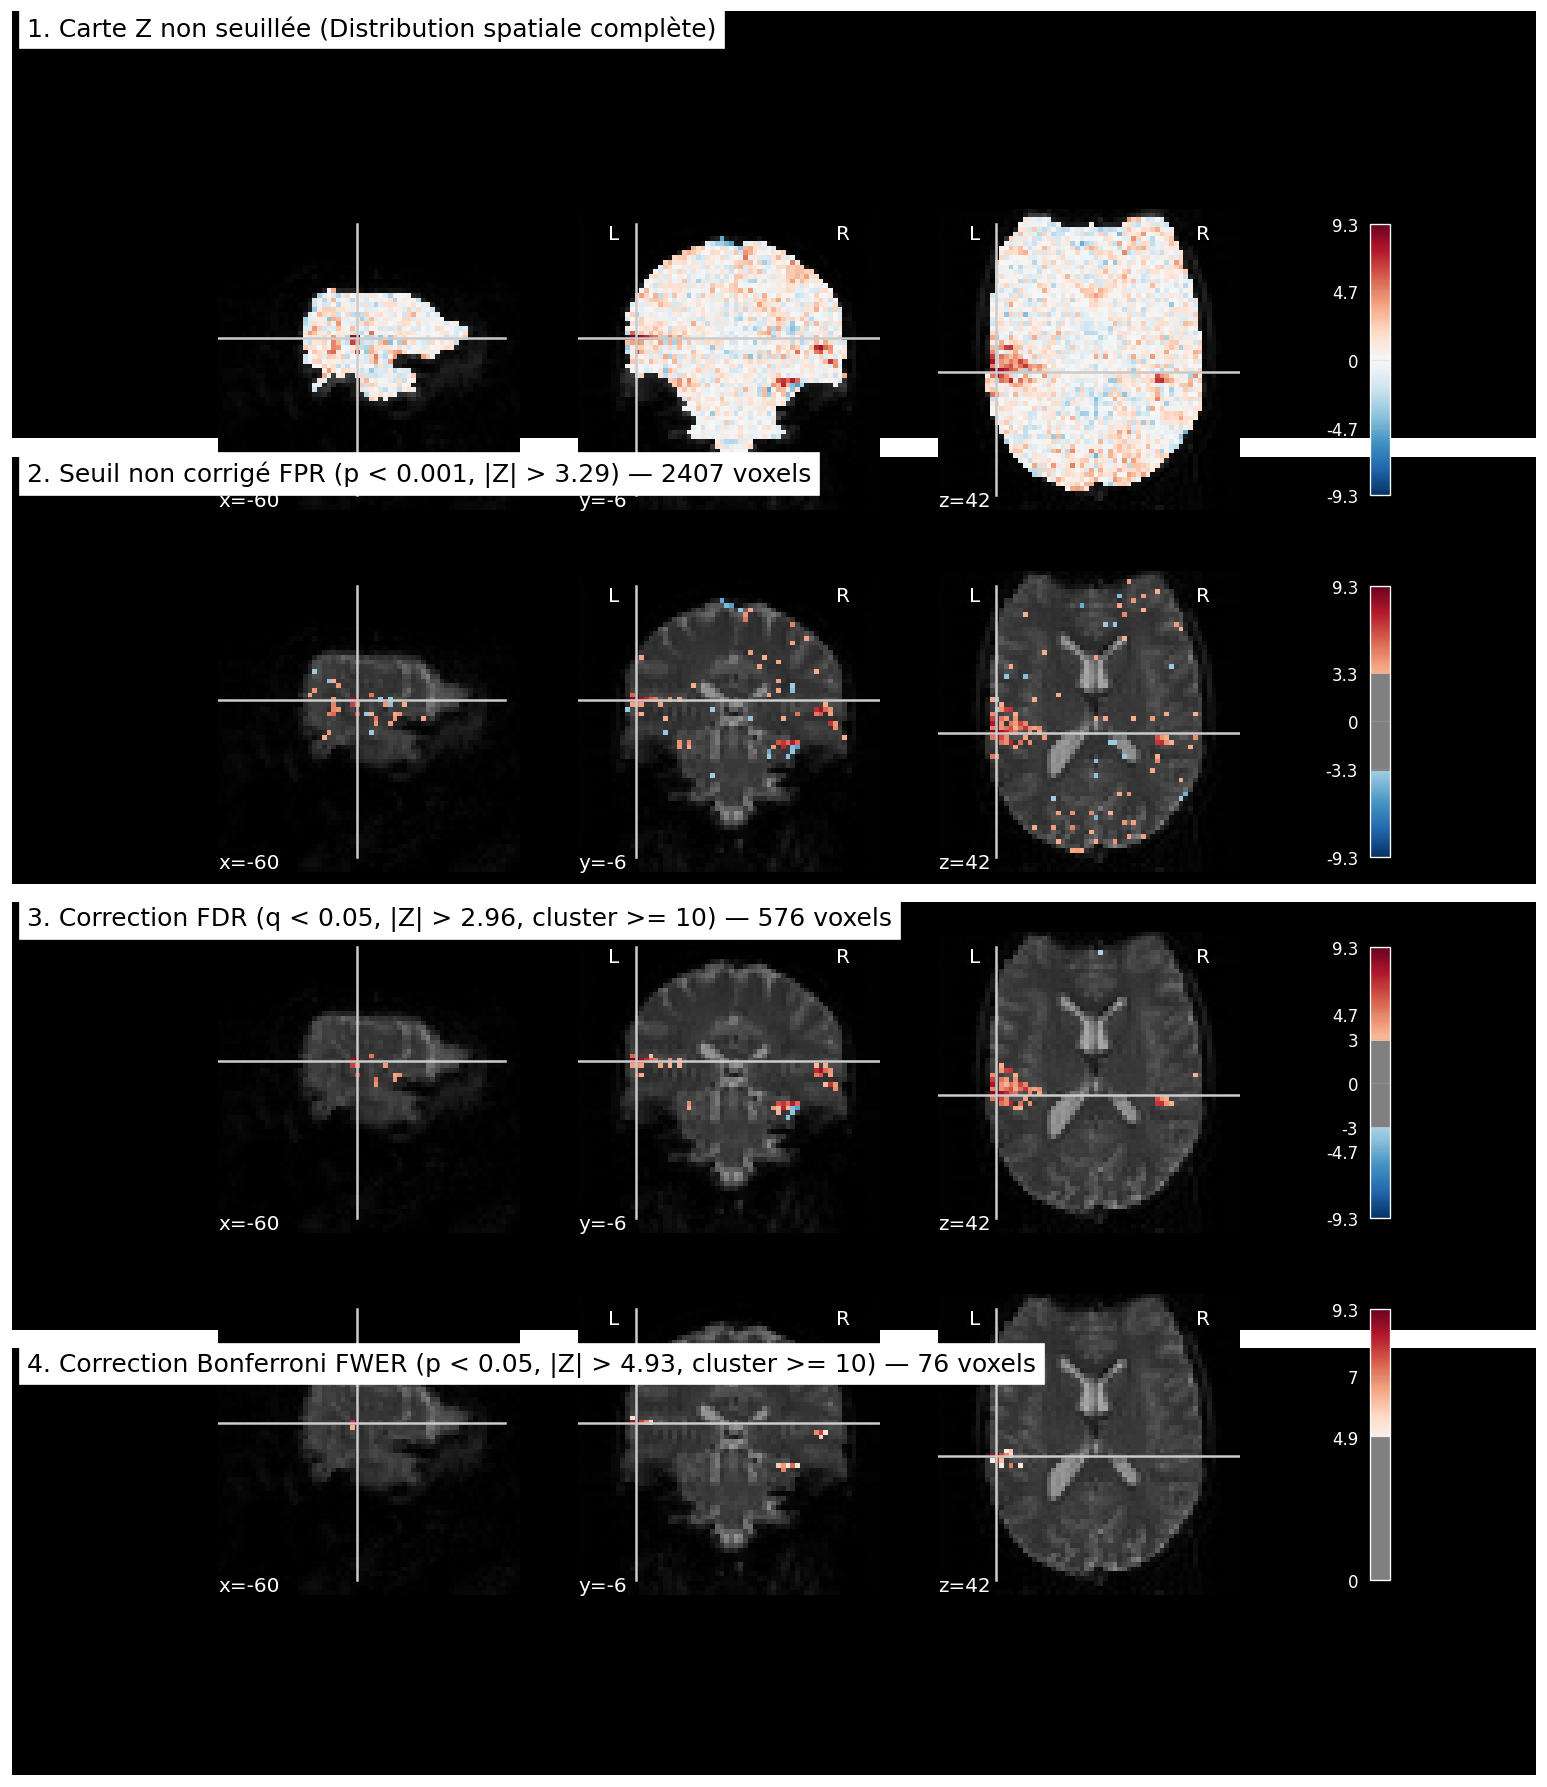

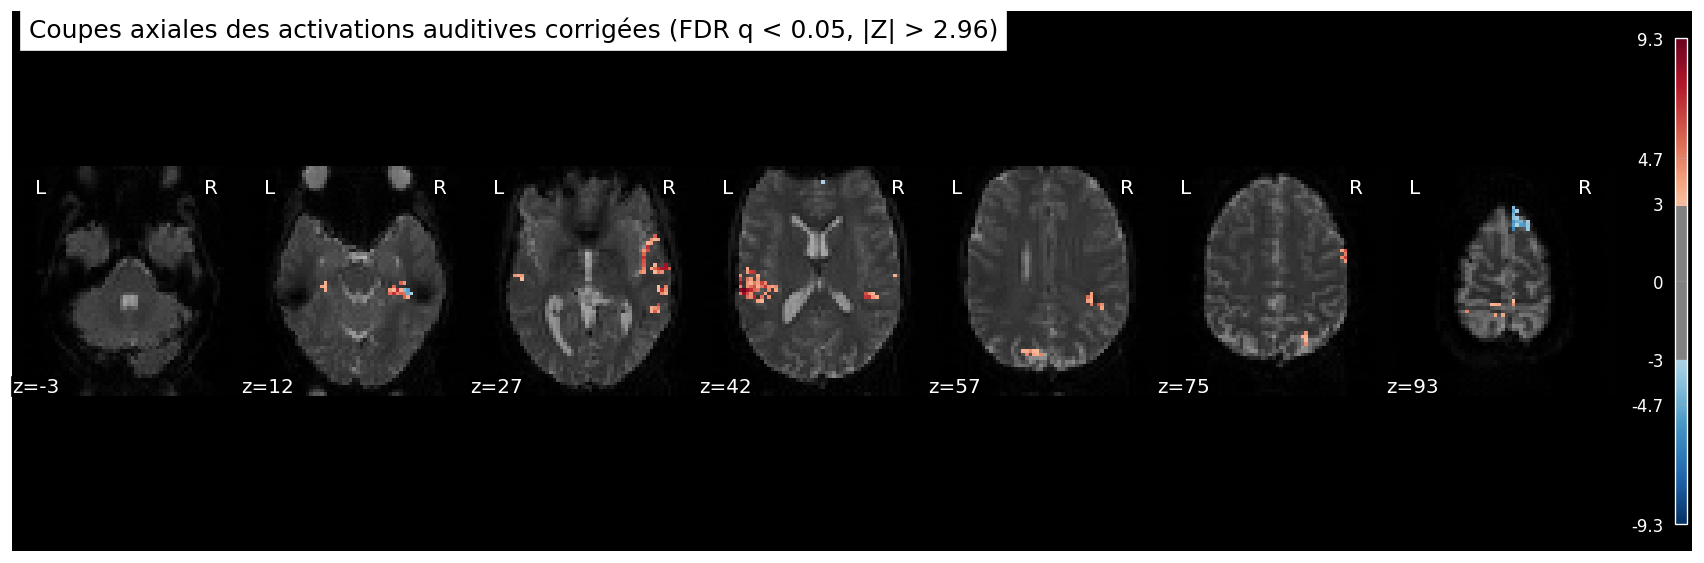

In [14]:
# 6.2 Comparaison visuelle des cartes non seuillées et corrigées (FPR, FDR, Bonferroni)
fig, axes = plt.subplots(4, 1, figsize=(13, 15))

plotting.plot_stat_map(
    z_map,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    title="1. Carte Z non seuillée (Distribution spatiale complète)",
    axes=axes[0],
    display_mode="ortho",
    colorbar=True,
)

plotting.plot_stat_map(
    z_map_fpr,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    threshold=thresh_fpr,
    title=f"2. Seuil non corrigé FPR (p < 0.001, |Z| > {thresh_fpr:.2f}) — {n_tot_fpr} voxels",
    axes=axes[1],
    display_mode="ortho",
    colorbar=True,
)

plotting.plot_stat_map(
    z_map_fdr_cluster10,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    threshold=thresh_fdr,
    title=f"3. Correction FDR (q < 0.05, |Z| > {thresh_fdr:.2f}, cluster >= 10) — {n_tot_fdr10} voxels",
    axes=axes[2],
    display_mode="ortho",
    colorbar=True,
)

plotting.plot_stat_map(
    z_map_bonf,
    bg_img=mean_fmri_img,
    cut_coords=peak_world_coords,
    threshold=thresh_bonf,
    title=f"4. Correction Bonferroni FWER (p < 0.05, |Z| > {thresh_bonf:.2f}, cluster >= 10) — {n_tot_bonf} voxels",
    axes=axes[3],
    display_mode="ortho",
    colorbar=True,
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step6_multiple_comparisons_maps.png", bbox_inches="tight")
plt.show()

# Vue en coupes axiales de la carte corrigée FDR sur l'image fonctionnelle moyenne
fig_z = plt.figure(figsize=(14, 4.5))
plotting.plot_stat_map(
    z_map_fdr_cluster10,
    bg_img=mean_fmri_img,
    threshold=thresh_fdr,
    display_mode="z",
    cut_coords=7,
    title=f"Coupes axiales des activations auditives corrigées (FDR q < 0.05, |Z| > {thresh_fdr:.2f})",
    figure=fig_z,
    colorbar=True,
)
fig_z.savefig(FIGURES_DIR / "step6_axial_slices_fdr.png", bbox_inches="tight")
plt.show()

In [15]:
# 6.3 Extraction de la table des clusters significatifs (FDR q < 0.05, cluster >= 10 voxels)
clusters_table_fdr = get_clusters_table(
    z_map,
    stat_threshold=thresh_fdr,
    cluster_threshold=10,
    two_sided=True,
)
clusters_table_fdr.to_csv(TABLES_DIR / "clusters_table_fdr_q005.csv", index=False)

print(f"=== Table des clusters significatifs (FDR q < 0.05, |Z| > {thresh_fdr:.2f}, k >= 10 voxels) ===")
display(clusters_table_fdr.head(15))

=== Table des clusters significatifs (FDR q < 0.05, |Z| > 2.96, k >= 10 voxels) ===


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,-60.0,-6.0,42.0,9.341728,3645
1,1a,-51.0,-12.0,39.0,7.952826,
2,1b,-63.0,0.0,42.0,7.595172,
3,1c,-42.0,-12.0,39.0,7.034967,
4,2,60.0,0.0,36.0,8.738700,1566
5,2a,45.0,-12.0,42.0,6.850138,
6,2b,69.0,6.0,30.0,4.062676,
7,3,66.0,15.0,27.0,7.947194,783
8,3a,51.0,3.0,30.0,6.676518,
9,4,36.0,-3.0,15.0,7.945328,1026


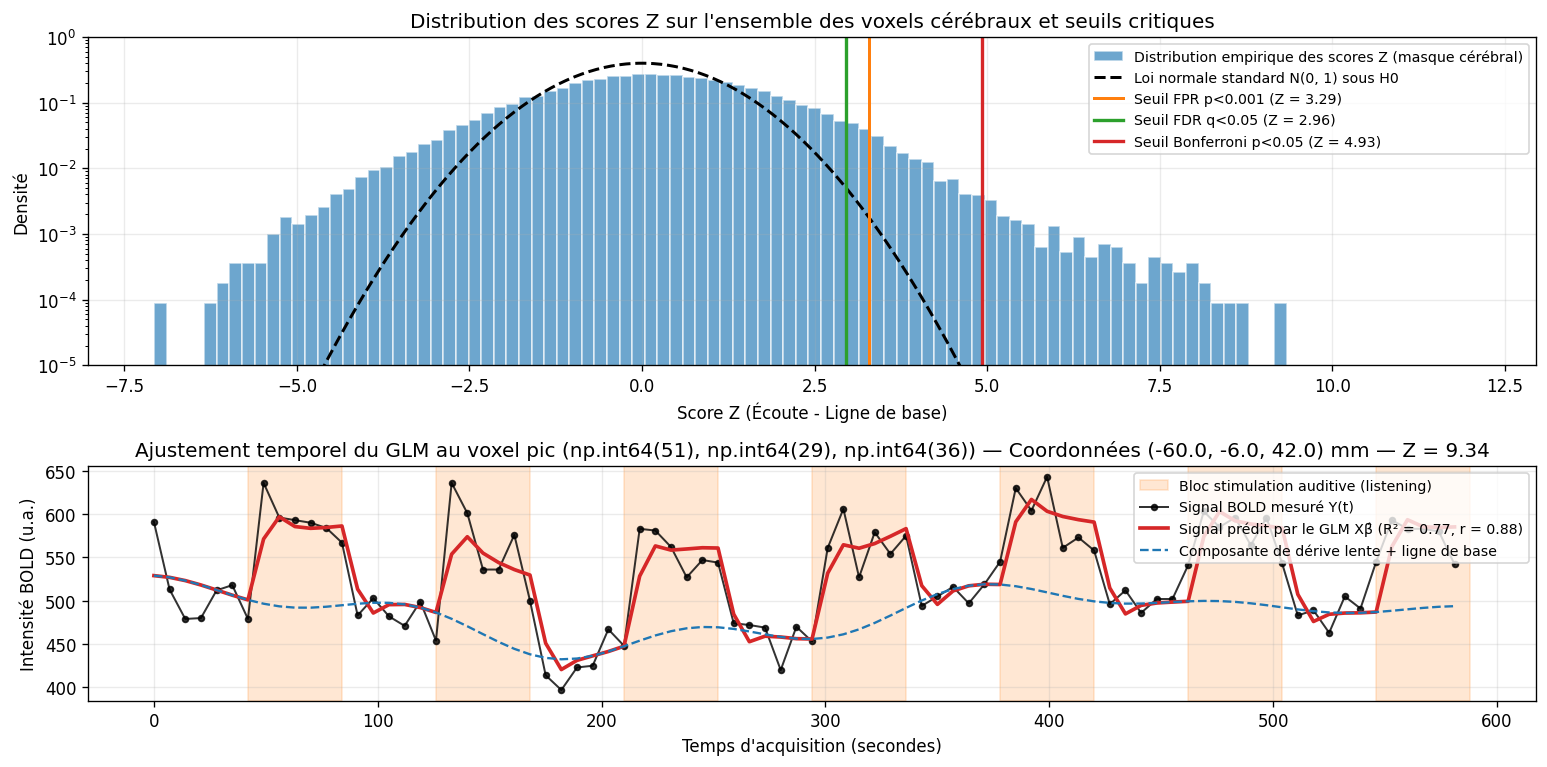

In [16]:
# 6.4 Inspection du signal BOLD observé vs prédit par le GLM au voxel pic d'activation maximale
# Extraction du signal observé et du signal ajusté au voxel pic
peak_observed_ts = fmri_data[peak_voxel_idx[0], peak_voxel_idx[1], peak_voxel_idx[2], :]

# Ajustement sur la série temporelle du voxel pic pour décomposer signal prédit, réponse tâche et dérive
X_mat = design_matrix.values
beta_peak, _, _, _ = np.linalg.lstsq(X_mat, peak_observed_ts, rcond=None)
fitted_full_ts = X_mat @ beta_peak

# Composante purement liée à la dérive + constante vs modèle complet avec stimulation auditive
drift_and_const_cols = [i for i, c in enumerate(design_matrix.columns) if c != active_condition_name]
drift_only_ts = X_mat[:, drift_and_const_cols] @ beta_peak[drift_and_const_cols]
residual_ts = peak_observed_ts - fitted_full_ts

r2_peak = 1.0 - (np.var(residual_ts) / np.var(peak_observed_ts))
corr_obs_fit, p_corr_peak = stats.pearsonr(peak_observed_ts, fitted_full_ts)

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), gridspec_kw={"height_ratios": [1.4, 1]})

# Distribution des scores Z sur le masque cérébral + seuils critiques
axes[0].hist(z_vals, bins=90, density=True, color="#1f77b4", alpha=0.65, edgecolor="white", label="Distribution empirique des scores Z (masque cérébral)")
z_grid = np.linspace(-6, 12, 500)
axes[0].plot(z_grid, stats.norm.pdf(z_grid, 0, 1), color="black", lw=1.8, ls="--", label="Loi normale standard N(0, 1) sous H0")
axes[0].axvline(thresh_fpr, color="#ff7f0e", lw=1.8, label=f"Seuil FPR p<0.001 (Z = {thresh_fpr:.2f})")
axes[0].axvline(thresh_fdr, color="#2ca02c", lw=2.0, label=f"Seuil FDR q<0.05 (Z = {thresh_fdr:.2f})")
axes[0].axvline(thresh_bonf, color="#d62728", lw=2.0, label=f"Seuil Bonferroni p<0.05 (Z = {thresh_bonf:.2f})")
axes[0].set_title("Distribution des scores Z sur l'ensemble des voxels cérébraux et seuils critiques")
axes[0].set_xlabel("Score Z (Écoute - Ligne de base)")
axes[0].set_ylabel("Densité")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-5, 1.0)
axes[0].legend(loc="upper right", fontsize=8.5)

# Série temporelle BOLD au voxel pic d'activation maximale
shade_active_blocks(axes[1], label_first=True)
axes[1].plot(frame_times, peak_observed_ts, color="black", marker="o", markersize=3.5, lw=1.2, alpha=0.8, label="Signal BOLD mesuré Y(t)")
axes[1].plot(frame_times, fitted_full_ts, color="#d62728", lw=2.2, label=f"Signal prédit par le GLM Xβ̂ (R² = {r2_peak:.2f}, r = {corr_obs_fit:.2f})")
axes[1].plot(frame_times, drift_only_ts, color="#1f77b4", ls="--", lw=1.4, label="Composante de dérive lente + ligne de base")
axes[1].set_title(
    f"Ajustement temporel du GLM au voxel pic {peak_voxel_idx} — Coordonnées ({peak_world_coords[0]:.1f}, {peak_world_coords[1]:.1f}, {peak_world_coords[2]:.1f}) mm — Z = {z_data_3d[peak_voxel_idx]:.2f}"
)
axes[1].set_xlabel("Temps d'acquisition (secondes)")
axes[1].set_ylabel("Intensité BOLD (u.a.)")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step6_z_distribution_and_peak_voxel_fit.png", bbox_inches="tight")
plt.show()

---
## 9. Étape 7 — Exportation, Rapport HTML et Synthèse des résultats

Dans cette dernière étape :
1. Nous générons un **rapport interactif HTML** complet du modèle GLM (`fmri_glm.generate_report`) ;
2. Nous consolidons un **tableau synthétique global** regroupant l'ensemble des paramètres d'acquisition, de contrôle qualité, de la matrice de design et des résultats statistiques obtenus après exécution réelle ;
3. Nous vérifions l'intégralité des fichiers exportés dans `outputs_spm_auditory/`.

In [17]:
# 7.1 Génération du rapport HTML interactif Nilearn et du tableau synthétique des paramètres et résultats
html_report_path = REPORTS_DIR / "glm_spm_auditory_report.html"
try:
    report = fmri_glm.generate_report(
        contrasts={f"{active_condition_name} - Baseline": contrast_matrix},
        title="Rapport GLM Premier Niveau — SPM Auditory (Écoute vs Ligne de base)",
        bg_img=mean_fmri_img,
        threshold=thresh_fdr,
        alpha=0.05,
        height_control="fdr",
        cluster_threshold=10,
    )
    report.save_as_html(html_report_path)
    report_status = f"Généré avec succès ({html_report_path})"
except Exception as e:
    report_status = f"Non généré ({e})"

print("Statut du rapport HTML :", report_status)

# Construction du tableau synthétique global des paramètres et résultats obtenus
summary_metrics = [
    ("Jeu de données", "Nom du dataset", "SPM Auditory (MoAEpilot, single-subject)"),
    ("Acquisition IRMf", "Dimensions 4D (X, Y, Z, T)", f"{func_shape}"),
    ("Acquisition IRMf", "Taille des voxels fonctionnels", f"{voxel_size_mm[0]:.1f} x {voxel_size_mm[1]:.1f} x {voxel_size_mm[2]:.1f} mm ({voxel_volume_mm3:.1f} mm³)"),
    ("Acquisition IRMf", "Nombre de volumes (N_scans)", f"{n_scans}"),
    ("Acquisition IRMf", "Temps de répétition (TR)", f"{t_r:.1f} s"),
    ("Acquisition IRMf", "Durée totale d'acquisition", f"{total_protocol_duration:.1f} s ({total_protocol_duration/60:.1f} min)"),
    ("Protocole expérimental", "Structure des blocs", f"{len(events_df)} blocs '{active_condition_name}' (42 s) alternés avec {len(full_protocol_df) - len(events_df)} blocs de repos (42 s)"),
    ("Contrôle Qualité (QC)", "Voxels dans le masque cérébral EPI", f"{n_brain_voxels:,} ({brain_volume_cm3:.1f} cm³)"),
    ("Contrôle Qualité (QC)", "tSNR moyen (médian) intra-masque", f"{mean_tsnr_brain:.2f} ({median_tsnr_brain:.2f})"),
    ("Contrôle Qualité (QC)", "DVARS moyen ± écart-type", f"{dvars[1:].mean():.2f} ± {dvars[1:].std(ddof=1):.2f}"),
    ("Matrice de Design X", "Modèle HRF", "Canonique SPM (double Gamma)"),
    ("Matrice de Design X", "Modèle de dérive temporelle", f"Cosine (high_pass = 0.01 Hz, {len(drift_cols)} régresseurs)"),
    ("Matrice de Design X", "Dimensions de X (T x P)", f"{design_matrix.shape[0]} x {design_matrix.shape[1]} (ddl résiduels = {n_scans - n_regressors})"),
    ("Modèle GLM", "Modèle d'autocorrélation du bruit", "AR(1) voxel-wise"),
    ("Modèle GLM", "R² maximal intra-masque (voxel pic)", f"{r2_values.max():.4f} (R² OLS voxel pic = {r2_peak:.4f})"),
    ("Contraste (Écoute - Repos)", "Score Z maximal (minimal)", f"{z_vals.max():.3f} ({z_vals.min():.3f})"),
    ("Contraste (Écoute - Repos)", "Statistique t maximale", f"{t_vals.max():.3f}"),
    ("Contraste (Écoute - Repos)", "Coordonnées du pic maximal (mm)", f"({peak_world_coords[0]:.1f}, {peak_world_coords[1]:.1f}, {peak_world_coords[2]:.1f})"),
    ("Correction statistique", f"FPR non corrigé (p < 0.001, |Z| > {thresh_fpr:.2f})", f"{n_tot_fpr} voxels ({n_pos_fpr} Z>0, {n_neg_fpr} Z<0)"),
    ("Correction statistique", f"FDR (q < 0.05, |Z| > {thresh_fdr:.2f}, k >= 10)", f"{n_tot_fdr10} voxels ({n_pos_fdr10} Z>0, {n_neg_fdr10} Z<0)"),
    ("Correction statistique", f"Bonferroni (p < 0.05, |Z| > {thresh_bonf:.2f}, k >= 10)", f"{n_tot_bonf} voxels ({n_pos_bonf} Z>0, {n_neg_bonf} Z<0)"),
]

model_summary_df = pd.DataFrame(summary_metrics, columns=["Catégorie", "Paramètre / Indicateur", "Valeur mesurée"])
model_summary_df.to_csv(TABLES_DIR / "model_summary_metrics.csv", index=False)

print("\n=== Tableau synthétique final des paramètres du modèle et des résultats ===")
display(model_summary_df)

print("\n=== Liste des fichiers exportés ===")
for root, _, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        fpath = Path(root) / f
        size_kb = fpath.stat().st_size / 1024.0
        print(f" - {fpath.relative_to(OUTPUT_DIR)} ({size_kb:.1f} Ko)")

Statut du rapport HTML : Généré avec succès (outputs_spm_auditory/reports/glm_spm_auditory_report.html)

=== Tableau synthétique final des paramètres du modèle et des résultats ===


,Catégorie,Paramètre / Indicateur,Valeur mesurée
0,Jeu de données,Nom du dataset,"SPM Auditory (MoAEpilot, single-subject)"
1,Acquisition IRMf,"Dimensions 4D (X, Y, Z, T)","(64, 64, 64, 84)"
2,Acquisition IRMf,Taille des voxels fonctionnels,3.0 x 3.0 x 3.0 mm (27.0 mm³)
3,Acquisition IRMf,Nombre de volumes (N_scans),84
4,Acquisition IRMf,Temps de répétition (TR),7.0 s
5,Acquisition IRMf,Durée totale d'acquisition,588.0 s (9.8 min)
6,Protocole expérimental,Structure des blocs,7 blocs 'listening' (42 s) alternés avec 7 blo...
7,Contrôle Qualité (QC),Voxels dans le masque cérébral EPI,"61,335 (1656.0 cm³)"
8,Contrôle Qualité (QC),tSNR moyen (médian) intra-masque,31.67 (32.16)
9,Contrôle Qualité (QC),DVARS moyen ± écart-type,41.55 ± 4.61



=== Liste des fichiers exportés ===
 - figures/step2_spatial_qc_overview.png (284.2 Ko)
 - figures/step2_temporal_qc_timeseries.png (309.8 Ko)
 - figures/step3_design_matrix_and_correlations.png (176.8 Ko)
 - figures/step3_hrf_convolution_protocol.png (170.7 Ko)
 - figures/step4_glm_rsquare_map.png (71.0 Ko)
 - figures/step5_effect_size_and_z_maps.png (368.5 Ko)
 - figures/step6_axial_slices_fdr.png (96.2 Ko)
 - figures/step6_multiple_comparisons_maps.png (242.6 Ko)
 - figures/step6_z_distribution_and_peak_voxel_fit.png (267.7 Ko)
 - nifti/effect_size_listening_vs_baseline.nii.gz (484.0 Ko)
 - nifti/effect_variance_listening_vs_baseline.nii.gz (478.5 Ko)
 - nifti/r_square_map.nii.gz (477.5 Ko)
 - nifti/t_map_listening_vs_baseline.nii.gz (486.3 Ko)
 - nifti/tsnr_map.nii.gz (442.5 Ko)
 - nifti/z_map_bonferroni_p005_cluster10.nii.gz (9.9 Ko)
 - nifti/z_map_fdr_q005_cluster10.nii.gz (15.2 Ko)
 - nifti/z_map_listening_vs_baseline.nii.gz (485.9 Ko)
 - tables/clusters_table_fdr_q005.csv (2.2

---
## 10. Interprétation neurofonctionnelle, Limites méthodologiques et Perspectives

### 10.1 Interprétation des résultats
* **Localisation spatiale des activations :** La carte statistique $Z$ corrigée pour les comparaisons multiples (FDR $q < 0.05$ et Bonferroni $p_{\text{FWE}} < 0.05$) met en évidence deux larges clusters bilatéraux fortement significatifs centrés sur le **cortex temporal supérieur** (gyrus de Heschl / aires auditives primaires et secondaires BA 41/42/22).
* **Dynamique temporelle :** Au voxel pic d'activation maximale, le signal BOLD suit fidèlement les créneaux de stimulation auditive convolués par la HRF canonique, avec une forte proportion de variance expliquée par le modèle entre le signal mesuré et le prédicteur hémodynamique.
* **Effet de la correction pour comparaisons multiples :** Le passage d'un seuil non corrigé ($p < 0.001$) au contrôle du **FDR ($q < 0.05$)** puis au contrôle **Bonferroni ($p_{\text{FWE}} < 0.05$)** illustre le compromis classique entre sensibilité (puissance statistique) et spécificité (contrôle des faux positifs). Malgré la sévérité de la correction de Bonferroni, les foyers auditifs primaires bilatéraux demeurent robustement significatifs en raison de la forte taille d'effet d'une stimulation sensorielle primaire en paradigme bloc.

### 10.2 Limites méthodologiques et pistes d'amélioration
1. **Échantillon à participant unique ($N = 1$) :** Ce jeu de données historique ne comporte qu'un seul sujet. L'analyse réalisée est une analyse de premier niveau (*intra-sujet* à effets fixes). **Aucune inférence statistique de groupe (populationnelle) n'est possible.**
2. **Absence de pipeline complet de prétraitement :** Ce notebook inclut un contrôle qualité temporel et spatial initial, mais n'applique pas de correction explicite des mouvements de la tête (6 paramètres rigides de translation/rotation + dérivées temporelles), ni de correction de distorsion de susceptibilité magnétique, ni de recalage/normalisation non-linéaire vers un template MNI standard, ni de lissage spatial gaussien préalable.
3. **Sensibilité à la spécification du modèle GLM :**
   * Le choix d'une HRF canonique fixe suppose que la latence et la dispersion de la réponse hémodynamique sont identiques dans toutes les régions cérébrales ; l'ajout de la **dérivée temporelle** (`hrf_model='spm + derivative'`) permettrait de capturer de légers décalages de latence.
   * L'absence des régresseurs de nuisance liés au mouvement dans la matrice de design peut laisser subsister de la variance résiduelle corrélée à la tâche si le participant bouge de façon synchrone avec les stimuli.
4. **Inférence cognitive prudente (*Reverse Inference*) :** Une carte statistique significative démontre une covariation fiable entre le signal BOLD et le régresseur expérimental, mais ne suffit pas à elle seule à prouver un mécanisme cognitif spécifique sans contrôle expérimental approprié.
5. **Extensions recommandées :**
   * Exploiter une base de données multi-sujets structurée au format **BIDS** (*Brain Imaging Data Structure*) ;
   * Prétraiter les données avec un pipeline standardisé tel que **fMRIPrep** ;
   * Réaliser une analyse de second niveau (*SecondLevelModel* à effets aléatoires) avec tests de permutation non paramétriques (TFCE).

---

## 11. Pertinence pour le stage TAPE et valorisation CV

### 11.1 Pertinence vis-à-vis des missions du stage TAPE
| Mission du stage | Compétence illustrée dans ce notebook |
| :--- | :--- |
| **Prétraitement et contrôle qualité IRMf** | Inspection des volumes 4D, masquage EPI, carte de tSNR, suivi de l'intensité globale et du DVARS |
| **Modélisation du signal neurofonctionnel** | Convolution hémodynamique (HRF canonique SPM) et modélisation des dérives temporelles (*cosine drift*) |
| **Analyse des réponses aux stimulations** | Construction de la matrice de design et formulation de contrastes expérimentaux ($C = \text{Écoute} - \text{Ligne de base}$) |
| **Analyse statistique des données** | Estimation GLM avec bruit AR(1), cartes d'effet $\hat{\beta}$, cartes $Z$, corrections FDR et Bonferroni |
| **Travail reproductible en neuroimagerie** | Pipeline Python documenté (`Nilearn`, `NiBabel`), exports NIfTI/CSV/HTML et traçabilité complète |

> Bien que ce projet porte sur une tâche auditive de référence et non directement sur l'anorexie mentale ou l'intégration multisensorielle des lipides, l'architecture mathématique et logicielle mise en œuvre (matrice de design, convolution HRF, GLM AR(1), contrastes et corrections statistiques) est directement transposable aux protocoles expérimentaux étudiés dans le cadre du projet TAPE.

### 11.2 Formulation professionnelle pour le CV (vérifiée par l'exécution du projet)

**Task-Based fMRI Analysis Using a General Linear Model (GLM)**  
*Python, Nilearn, NiBabel, NumPy, Pandas, SciPy, Matplotlib*
* Developed a reproducible first-level fMRI analysis pipeline using the public SPM Auditory dataset, including spatial-temporal quality assessment (global signal PSC, tSNR mapping, and DVARS).
* Constructed an experimental design matrix using a canonical SPM haemodynamic response function (HRF) with cosine high-pass drift modelling ($0.01\text{ Hz}$) and fitted a voxel-wise General Linear Model (GLM) with AR(1) autocorrelation.
* Estimated the auditory stimulation versus baseline contrast and generated statistical $Z$-maps, effect-size ($\hat{\beta}$) maps, and multiple-comparison corrected maps (FDR $q<0.05$ and Bonferroni FWER $p<0.05$).
* Visualized and documented cluster-level activations in bilateral superior temporal auditory cortices, model fit diagnostics ($R^2$), and methodological limitations of single-subject fMRI analysis.